In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


2. Important library import

In [ ]:

import os
import torch
import numpy as np

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch version: 2.14.1+cpu
CUDA available: False


3. Specify the dataset path

In [ ]:

BASE_PATH = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"

CLASSIFICATION_PATH = os.path.join(
    BASE_PATH,
    "BRISC_classification_256"
)

print("Dataset path:", CLASSIFICATION_PATH)
print("Path exists:", os.path.exists(CLASSIFICATION_PATH))

print("Train classes:",
      os.listdir(os.path.join(CLASSIFICATION_PATH, "train")))


Dataset path: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/BRISC_classification_256
Path exists: True
Train classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


4. Create a Dataset class

In [ ]:

class BRISCClassificationDataset(Dataset):

    def __init__(self, root_dir, transform=None):

        self.root_dir = root_dir
        self.transform = transform

        self.classes = [
            "glioma",
            "meningioma",
            "no_tumor",
            "pituitary"
        ]

        self.class_to_idx = {
            class_name: idx
            for idx, class_name in enumerate(self.classes)
        }

        self.samples = []

        for class_name in self.classes:

            class_dir = os.path.join(
                root_dir, class_name
            )

            for filename in sorted(os.listdir(class_dir)):

                file_path = os.path.join(
                    class_dir, filename
                )

                if filename.lower().endswith(
                    (".jpg", ".jpeg", ".png")
                ):

                    label = self.class_to_idx[class_name]

                    self.samples.append(
                        (file_path, label)
                    )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


5. Create an Image Transform

In [ ]:

transform = transforms.Compose([
    transforms.ToTensor()
])


6. Create Train and Test Datasets

In [ ]:

train_path = os.path.join(CLASSIFICATION_PATH, "train")
test_path = os.path.join(CLASSIFICATION_PATH, "test")

train_dataset = BRISCClassificationDataset(
    root_dir=train_path,
    transform=transform
)

test_dataset = BRISCClassificationDataset(
    root_dir=test_path,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))


Training images: 5000
Testing images: 1000


7. Create a DataLoader

In [ ]:

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))


Training batches: 313
Testing batches: 63


8. Test a batch

In [ ]:

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Image value range:",
      images.min().item(),
      images.max().item())

print("Labels:", labels)


Image batch shape: torch.Size([16, 3, 256, 256])
Label batch shape: torch.Size([16])
Image value range: 0.0 1.0
Labels: tensor([1, 0, 3, 3, 3, 0, 2, 1, 1, 0, 1, 3, 2, 1, 0, 3])


9. View the image and label together

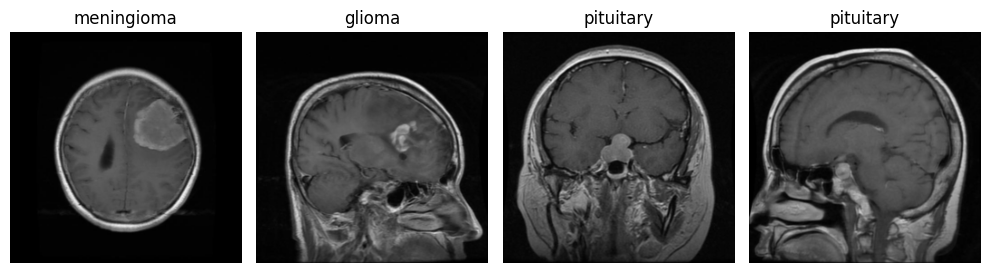

In [ ]:

import matplotlib.pyplot as plt

class_names = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]

plt.figure(figsize=(10, 5))

for i in range(4):

    image = images[i].permute(1, 2, 0).numpy()
    label = labels[i].item()

    plt.subplot(1, 4, i + 1)
    plt.imshow(image)
    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()


Step 2 — EfficientNet-B0 Baseline Classification

1. Create train and validation splits.


In [ ]:

from torch.utils.data import random_split, DataLoader

train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size

generator = torch.Generator().manual_seed(42)

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=generator
)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Testing samples:", len(test_dataset))


Training samples: 4000
Validation samples: 1000
Testing samples: 1000


2. Image Preprocessing for EfficientNet


In [ ]:

from torchvision.models import EfficientNet_B0_Weights

weights = EfficientNet_B0_Weights.DEFAULT

transform = weights.transforms()

train_dataset.transform = transform

train_loader = DataLoader(
    train_subset,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_subset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

print("Image preprocessing completed.")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Image preprocessing completed.
Training batches: 250
Validation batches: 63


3. Selecting a device

In [ ]:

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


Using device: cpu


4. Building the EfficientNet-B0 Model

In [ ]:

import torch.nn as nn
from torchvision.models import efficientnet_b0

model = efficientnet_b0(weights=weights)

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    4
)

model = model.to(device)

print(model.classifier)
print("EfficientNet-B0 model is ready.")


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 85.1MB/s]


Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)
EfficientNet-B0 model is ready.


5. Creating the Loss Function and Optimizer

In [ ]:

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)


Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.01
)


6. Creating Training and Validation Functions

In [ ]:

def run_epoch(model, loader, criterion, optimizer=None):

    if optimizer is not None:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if optimizer is not None:
            optimizer.zero_grad()

        with torch.set_grad_enabled(optimizer is not None):

            outputs = model(images)
            loss = criterion(outputs, labels)

            if optimizer is not None:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = total_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


Step 2: Check if a GPU is present

In [ ]:

import torch

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("GPU is not available. CPU is being used.")


CUDA Available: False
GPU is not available. CPU is being used.


Step 3: Create a lightweight DataLoader

In [ ]:

BATCH_SIZE = 8

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training batches: 500
Validation batches: 125


Step 4: Test the model using a batch

In [ ]:

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Batch test successful.")


Input shape: torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8, 4])
Batch test successful.


Step 1 — Quick test on the CPU

In [ ]:
import torch
from tqdm.auto import tqdm

# Use a small subset for testing
small_train_subset = torch.utils.data.Subset(
    train_subset,
    range(0, 128)
)

small_val_subset = torch.utils.data.Subset(
    val_subset,
    range(0, 32)
)

train_loader = DataLoader(
    small_train_subset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    small_val_subset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Training samples:", len(small_train_subset))
print("Validation samples:", len(small_val_subset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training samples: 128
Validation samples: 32
Training batches: 16
Validation batches: 4


Step 2 — Epoch Training Test

In [ ]:
model.train()

total_loss = 0.0
correct = 0
total = 0

for images, labels in tqdm(train_loader, desc="Training Test"):

    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    total_loss += loss.item()

    predictions = torch.argmax(outputs, dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

average_loss = total_loss / len(train_loader)
accuracy = 100 * correct / total

print("Training Test Completed")
print("Average Loss:", round(average_loss, 4))
print("Accuracy:", round(accuracy, 2), "%")

Training Test:   0%|          | 0/16 [00:00<?, ?it/s]

Training Test Completed
Average Loss: 1.3516
Accuracy: 31.25 %


Step 7 — EfficientNet-B0 Model Training

In [ ]:

import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from tqdm.auto import tqdm

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load pretrained EfficientNet-B0
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Replace classifier for four classes
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 4)
model = model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001
)

# Create DataLoaders
BATCH_SIZE = 8

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Training and validation function
def run_epoch(model, loader, criterion, optimizer=None):

    if optimizer is not None:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader):

        images = images.to(device)
        labels = labels.to(device)

        if optimizer is not None:
            optimizer.zero_grad()

        with torch.set_grad_enabled(optimizer is not None):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if optimizer is not None:
                loss.backward()
                optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / len(loader)
    accuracy = 100 * correct / total

    return average_loss, accuracy


# Save directory
SAVE_DIR = os.path.join(BASE_PATH, "model_outputs")
os.makedirs(SAVE_DIR, exist_ok=True)

# Training configuration
EPOCHS = 1

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_loss = float("inf")

# Training loop
for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_accuracy = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_accuracy = run_epoch(
        model,
        val_loader,
        criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    print("Training Loss:", round(train_loss, 4))
    print("Validation Loss:", round(val_loss, 4))
    print("Training Accuracy:", round(train_accuracy, 2), "%")
    print("Validation Accuracy:", round(val_accuracy, 2), "%")

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            os.path.join(SAVE_DIR, "efficientnet_b0_best.pth")
        )

        print("Best model saved.")

print("\nTraining Completed.")


Device: cpu

Epoch 1/1


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/125 [00:00<?, ?it/s]

Training Loss: 0.4133
Validation Loss: 0.1198
Training Accuracy: 86.7 %
Validation Accuracy: 95.6 %
Best model saved.

Training Completed.


Step 8 — Training Graph Visualization

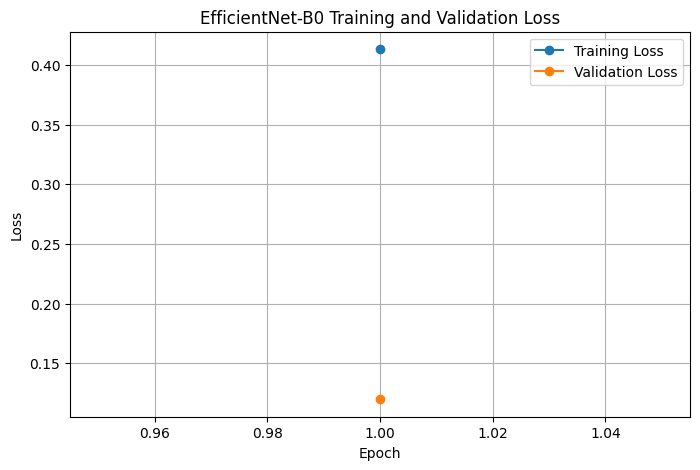

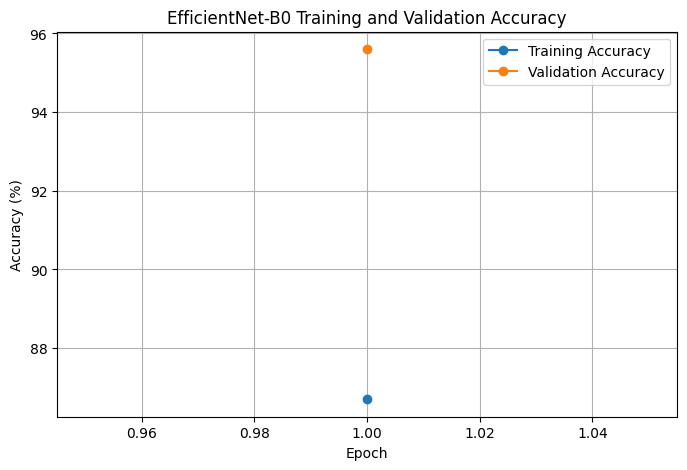

In [ ]:

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNet-B0 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("EfficientNet-B0 Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


Step 9 — Best Model Test Evaluation

Test Accuracy: 94.4 %

Classification Report:

              precision    recall  f1-score   support

      glioma       0.98      0.93      0.95       254
  meningioma       0.93      0.89      0.91       306
    no_tumor       0.90      0.99      0.94       140
   pituitary       0.96      0.99      0.98       300

    accuracy                           0.94      1000
   macro avg       0.94      0.95      0.94      1000
weighted avg       0.94      0.94      0.94      1000



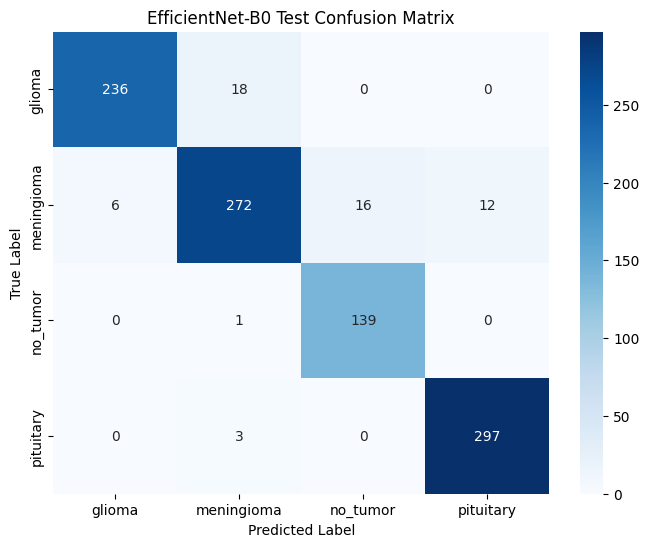

In [ ]:

import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Apply the same preprocessing to test images
weights = EfficientNet_B0_Weights.DEFAULT
test_dataset.transform = weights.transforms()

# Create test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# Create model architecture
model = efficientnet_b0(weights=None)

in_features = model.classifier[1].in_features
model.classifier[1] = torch.nn.Linear(in_features, 4)

# Load the best trained model
model_path = os.path.join(
    BASE_PATH,
    "model_outputs",
    "efficientnet_b0_best.pth"
)

model.load_state_dict(
    torch.load(model_path, map_location=device)
)

model = model.to(device)
model.eval()

# Collect predictions
all_predictions = []
all_labels = []

with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Calculate test accuracy
test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# Classification report
class_names = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]

print("\nClassification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("EfficientNet-B0 Test Confusion Matrix")
plt.show()


Step 10 — BRISC Tumor Segmentation start

In [ ]:

import os
from glob import glob
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms

# Dataset paths
SEGMENTATION_PATH = os.path.join(
    BASE_PATH,
    "BRISC_preprocessed_256_v2"
)

TRAIN_IMAGE_PATH = os.path.join(
    SEGMENTATION_PATH, "train", "images"
)

TRAIN_MASK_PATH = os.path.join(
    SEGMENTATION_PATH, "train", "masks"
)

TEST_IMAGE_PATH = os.path.join(
    SEGMENTATION_PATH, "test", "images"
)

TEST_MASK_PATH = os.path.join(
    SEGMENTATION_PATH, "test", "masks"
)

# Image transformation
image_transform = transforms.ToTensor()

# Custom segmentation dataset
class BRISCSegmentationDataset(Dataset):

    def __init__(self, image_dir, mask_dir):

        self.image_dir = image_dir
        self.mask_dir = mask_dir

        image_files = glob(os.path.join(image_dir, "*"))
        mask_files = glob(os.path.join(mask_dir, "*"))

        image_map = {
            os.path.splitext(os.path.basename(f))[0]: f
            for f in image_files
        }

        mask_map = {
            os.path.splitext(os.path.basename(f))[0]: f
            for f in mask_files
        }

        common_names = sorted(
            set(image_map.keys()) & set(mask_map.keys())
        )

        if len(common_names) == 0:
            raise ValueError("No matching image-mask pairs found.")

        if len(image_map) != len(mask_map):
            raise ValueError("Image and mask counts do not match.")

        if len(common_names) != len(image_map):
            raise ValueError("Some image-mask filenames do not match.")

        self.image_paths = [
            image_map[name] for name in common_names
        ]

        self.mask_paths = [
            mask_map[name] for name in common_names
        ]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):

        image = Image.open(
            self.image_paths[index]
        ).convert("RGB")

        mask = Image.open(
            self.mask_paths[index]
        ).convert("L")

        image = image_transform(image)

        mask = torch.from_numpy(
            __import__("numpy").array(mask).copy()
        ).float().unsqueeze(0) / 255.0

        return image, mask


# Create datasets
seg_train_dataset = BRISCSegmentationDataset(
    TRAIN_IMAGE_PATH,
    TRAIN_MASK_PATH
)

seg_test_dataset = BRISCSegmentationDataset(
    TEST_IMAGE_PATH,
    TEST_MASK_PATH
)

# Split training data into train and validation
train_size = int(0.8 * len(seg_train_dataset))
val_size = len(seg_train_dataset) - train_size

seg_train_subset, seg_val_subset = random_split(
    seg_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# Create DataLoaders
seg_train_loader = DataLoader(
    seg_train_subset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

seg_val_loader = DataLoader(
    seg_val_subset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

seg_test_loader = DataLoader(
    seg_test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# Check dataset
print("Training images:", len(seg_train_subset))
print("Validation images:", len(seg_val_subset))
print("Test images:", len(seg_test_dataset))

images, masks = next(iter(seg_train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image value range:", images.min().item(), images.max().item())
print("Mask value range:", masks.min().item(), masks.max().item())

print("Segmentation Dataset Loading Successful.")


Training images: 3146
Validation images: 787
Test images: 860
Image batch shape: torch.Size([8, 3, 256, 256])
Mask batch shape: torch.Size([8, 1, 256, 256])
Image value range: 0.0 0.9411764740943909
Mask value range: 0.0 1.0
Segmentation Dataset Loading Successful.


Step 11 — create U-Net Model

In [ ]:

import torch
import torch.nn as nn

# Convolution block
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# U-Net architecture
class UNet(nn.Module):

    def __init__(self):

        super().__init__()

        self.pool = nn.MaxPool2d(kernel_size=2)

        self.encoder1 = ConvBlock(3, 16)
        self.encoder2 = ConvBlock(16, 32)
        self.encoder3 = ConvBlock(32, 64)
        self.encoder4 = ConvBlock(64, 128)

        self.bottleneck = ConvBlock(128, 256)

        self.upconv4 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.decoder4 = ConvBlock(256, 128)

        self.upconv3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.decoder3 = ConvBlock(128, 64)

        self.upconv2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.decoder2 = ConvBlock(64, 32)

        self.upconv1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.decoder1 = ConvBlock(32, 16)

        self.output_layer = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):

        # Encoder
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder
        d4 = self.upconv4(b)
        d4 = torch.cat((e4, d4), dim=1)
        d4 = self.decoder4(d4)

        d3 = self.upconv3(d4)
        d3 = torch.cat((e3, d3), dim=1)
        d3 = self.decoder3(d3)

        d2 = self.upconv2(d3)
        d2 = torch.cat((e2, d2), dim=1)
        d2 = self.decoder2(d2)

        d1 = self.upconv1(d2)
        d1 = torch.cat((e1, d1), dim=1)
        d1 = self.decoder1(d1)

        output = self.output_layer(d1)

        return output


# Initialize U-Net
unet_model = UNet().to(device)

# Define loss function and optimizer
seg_criterion = nn.BCEWithLogitsLoss()

seg_optimizer = torch.optim.Adam(
    unet_model.parameters(),
    lr=0.001
)

print("U-Net model created successfully.")

# Test one batch
images, masks = next(iter(seg_train_loader))

images = images.to(device)
masks = masks.to(device)

unet_model.train()

seg_optimizer.zero_grad()

outputs = unet_model(images)

loss = seg_criterion(outputs, masks)

loss.backward()
seg_optimizer.step()

print("Input shape:", images.shape)
print("Mask shape:", masks.shape)
print("Output shape:", outputs.shape)
print("Test Loss:", loss.item())
print("U-Net batch test successful.")


U-Net model created successfully.
Input shape: torch.Size([8, 3, 256, 256])
Mask shape: torch.Size([8, 1, 256, 256])
Output shape: torch.Size([8, 1, 256, 256])
Test Loss: 0.6323517560958862
U-Net batch test successful.


Step 12 — U-Net Training and Validation

In [ ]:

import os
import torch
import torch.nn as nn
from tqdm.auto import tqdm

# Initialize a fresh U-Net model
unet_model = UNet().to(device)

# Define loss function and optimizer
seg_criterion = nn.BCEWithLogitsLoss()

seg_optimizer = torch.optim.Adam(
    unet_model.parameters(),
    lr=0.001
)

# Dice score function
def calculate_dice(outputs, masks):

    predictions = torch.sigmoid(outputs)
    predictions = (predictions > 0.5).float()

    intersection = (predictions * masks).sum(dim=(1, 2, 3))

    total = (
        predictions.sum(dim=(1, 2, 3)) +
        masks.sum(dim=(1, 2, 3))
    )

    dice = (2 * intersection + 1e-7) / (total + 1e-7)

    return dice.mean().item()


# Training function
def train_segmentation_epoch():

    unet_model.train()

    total_loss = 0.0
    total_dice = 0.0

    for images, masks in tqdm(
        seg_train_loader,
        desc="U-Net Training"
    ):

        images = images.to(device)
        masks = masks.to(device)

        seg_optimizer.zero_grad()

        outputs = unet_model(images)
        loss = seg_criterion(outputs, masks)

        loss.backward()
        seg_optimizer.step()

        total_loss += loss.item()
        total_dice += calculate_dice(outputs.detach(), masks)

    average_loss = total_loss / len(seg_train_loader)
    average_dice = total_dice / len(seg_train_loader)

    return average_loss, average_dice


# Validation function
def validate_segmentation_epoch():

    unet_model.eval()

    total_loss = 0.0
    total_dice = 0.0

    with torch.inference_mode():

        for images, masks in tqdm(
            seg_val_loader,
            desc="U-Net Validation"
        ):

            images = images.to(device)
            masks = masks.to(device)

            outputs = unet_model(images)

            loss = seg_criterion(outputs, masks)

            total_loss += loss.item()
            total_dice += calculate_dice(outputs, masks)

    average_loss = total_loss / len(seg_val_loader)
    average_dice = total_dice / len(seg_val_loader)

    return average_loss, average_dice


# Save directory
SEG_SAVE_DIR = os.path.join(
    BASE_PATH,
    "model_outputs"
)

os.makedirs(SEG_SAVE_DIR, exist_ok=True)

# Training configuration
SEG_EPOCHS = 1

seg_history = {
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": []
}

best_val_loss = float("inf")

# Training loop
for epoch in range(SEG_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{SEG_EPOCHS}")

    train_loss, train_dice = train_segmentation_epoch()

    val_loss, val_dice = validate_segmentation_epoch()

    seg_history["train_loss"].append(train_loss)
    seg_history["val_loss"].append(val_loss)
    seg_history["train_dice"].append(train_dice)
    seg_history["val_dice"].append(val_dice)

    print("Training Loss:", round(train_loss, 4))
    print("Validation Loss:", round(val_loss, 4))
    print("Training Dice:", round(train_dice, 4))
    print("Validation Dice:", round(val_dice, 4))

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            unet_model.state_dict(),
            os.path.join(
                SEG_SAVE_DIR,
                "unet_brisc_best.pth"
            )
        )

        print("Best U-Net model saved.")

print("\nU-Net Training Completed.")



Epoch 1/1


U-Net Training:   0%|          | 0/394 [00:00<?, ?it/s]

U-Net Validation:   0%|          | 0/99 [00:00<?, ?it/s]

Training Loss: 0.2524
Validation Loss: 0.0928
Training Dice: 0.272
Validation Dice: 0.4487
Best U-Net model saved.

U-Net Training Completed.


Step 13 — Training Graph

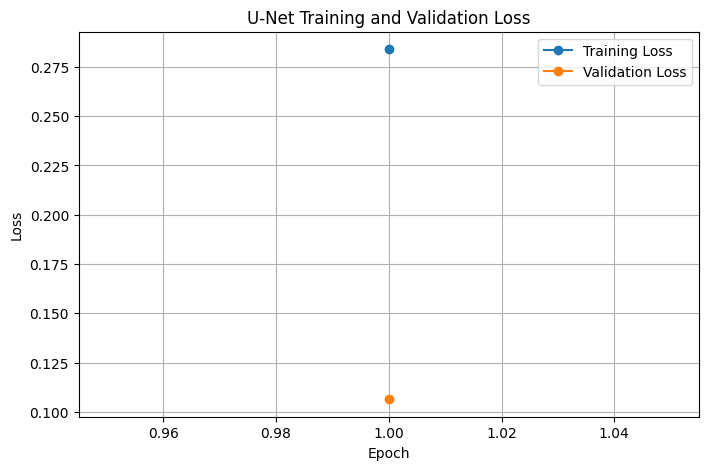

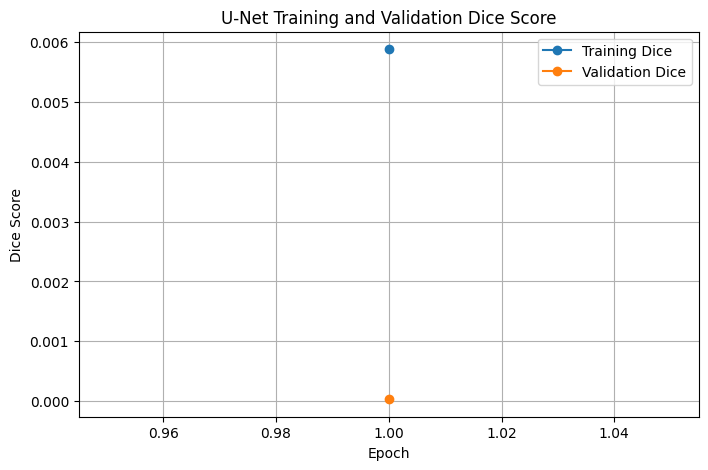

In [ ]:

import matplotlib.pyplot as plt

epochs = range(1, len(seg_history["train_loss"]) + 1)

# Loss graph
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    seg_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    seg_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("U-Net Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# Dice graph
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    seg_history["train_dice"],
    marker="o",
    label="Training Dice"
)

plt.plot(
    epochs,
    seg_history["val_dice"],
    marker="o",
    label="Validation Dice"
)

plt.xlabel("Epoch")
plt.ylabel("Dice Score")
plt.title("U-Net Training and Validation Dice Score")
plt.legend()
plt.grid(True)
plt.show()


2. Revision to Step 12 — U-Net Training using Combined Loss

In [ ]:

import os
import torch
import torch.nn as nn
from tqdm.auto import tqdm

# Create a fresh U-Net model
unet_model = UNet().to(device)

# Weighted BCE Loss
positive_weight = torch.tensor(
    [65.7],
    device=device
)

bce_criterion = nn.BCEWithLogitsLoss(
    pos_weight=positive_weight
)

# Combined BCE and Dice Loss
def combined_loss(outputs, masks):

    bce_loss = bce_criterion(outputs, masks)

    probabilities = torch.sigmoid(outputs)

    intersection = (
        probabilities * masks
    ).sum(dim=(1, 2, 3))

    total = (
        probabilities.sum(dim=(1, 2, 3)) +
        masks.sum(dim=(1, 2, 3))
    )

    dice_score = (
        2 * intersection + 1e-7
    ) / (total + 1e-7)

    dice_loss = 1 - dice_score.mean()

    return bce_loss + dice_loss


# Optimizer
seg_optimizer = torch.optim.Adam(
    unet_model.parameters(),
    lr=0.0005
)


# Training function
def train_segmentation_epoch():

    unet_model.train()

    total_loss = 0.0
    total_dice = 0.0

    for images, masks in tqdm(
        seg_train_loader,
        desc="U-Net Training"
    ):

        images = images.to(device)
        masks = masks.to(device)

        seg_optimizer.zero_grad()

        outputs = unet_model(images)

        loss = combined_loss(outputs, masks)

        loss.backward()
        seg_optimizer.step()

        total_loss += loss.item()

        total_dice += calculate_dice(
            outputs.detach(),
            masks
        )

    return (
        total_loss / len(seg_train_loader),
        total_dice / len(seg_train_loader)
    )


# Validation function
def validate_segmentation_epoch():

    unet_model.eval()

    total_loss = 0.0
    total_dice = 0.0

    with torch.inference_mode():

        for images, masks in tqdm(
            seg_val_loader,
            desc="U-Net Validation"
        ):

            images = images.to(device)
            masks = masks.to(device)

            outputs = unet_model(images)

            loss = combined_loss(outputs, masks)

            total_loss += loss.item()

            total_dice += calculate_dice(
                outputs,
                masks
            )

    return (
        total_loss / len(seg_val_loader),
        total_dice / len(seg_val_loader)
    )


# Save directory
SEG_SAVE_DIR = os.path.join(
    BASE_PATH,
    "model_outputs"
)

os.makedirs(SEG_SAVE_DIR, exist_ok=True)

# Train for one epoch initially
SEG_EPOCHS = 1

seg_history = {
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": []
}

best_val_loss = float("inf")

for epoch in range(SEG_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{SEG_EPOCHS}")

    train_loss, train_dice = train_segmentation_epoch()

    val_loss, val_dice = validate_segmentation_epoch()

    seg_history["train_loss"].append(train_loss)
    seg_history["val_loss"].append(val_loss)
    seg_history["train_dice"].append(train_dice)
    seg_history["val_dice"].append(val_dice)

    print("Training Loss:", round(train_loss, 4))
    print("Validation Loss:", round(val_loss, 4))
    print("Training Dice:", round(train_dice, 4))
    print("Validation Dice:", round(val_dice, 4))

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            unet_model.state_dict(),
            os.path.join(
                SEG_SAVE_DIR,
                "unet_brisc_weighted_best.pth"
            )
        )

        print("Best weighted U-Net model saved.")

print("\nWeighted U-Net Training Completed.")



Epoch 1/1


U-Net Training:   0%|          | 0/394 [00:00<?, ?it/s]

U-Net Validation:   0%|          | 0/99 [00:00<?, ?it/s]

Training Loss: 1.5365
Validation Loss: 1.3954
Training Dice: 0.1988
Validation Dice: 0.1692
Best weighted U-Net model saved.

Weighted U-Net Training Completed.


Step 13 — Weighted U-Net Diagnostic Check

In [ ]:
import os
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create the same U-Net architecture
unet_model = UNet().to(device)

# Load the weighted model
model_path = os.path.join(
    BASE_PATH,
    "model_outputs",
    "unet_brisc_weighted_best.pth"
)

checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=True
)

unet_model.load_state_dict(checkpoint)
unet_model.eval()

# Get one validation batch
images, masks = next(iter(seg_val_loader))

images = images.to(device)
masks = masks.to(device)

# Generate predictions
with torch.inference_mode():
    outputs = unet_model(images)
    probabilities = torch.sigmoid(outputs)
    predictions = (probabilities > 0.5).float()

# Print diagnostic results
print("Ground Truth Foreground Ratio:",
      round(masks.mean().item() * 100, 4), "%")

print("Predicted Foreground Ratio:",
      round(predictions.mean().item() * 100, 4), "%")

print("Mean Predicted Probability:",
      round(probabilities.mean().item(), 6))

print("Minimum Probability:",
      round(probabilities.min().item(), 6))

print("Maximum Probability:",
      round(probabilities.max().item(), 6))

print("Ground Truth Unique Values:",
      torch.unique(masks).cpu().tolist())

print("Predicted Unique Values:",
      torch.unique(predictions).cpu().tolist())

print("Diagnostic check completed.")

Ground Truth Foreground Ratio: 1.4994 %
Predicted Foreground Ratio: 17.4181 %
Mean Predicted Probability: 0.225444
Minimum Probability: 0.020444
Maximum Probability: 0.999981
Ground Truth Unique Values: [0.0, 1.0]
Predicted Unique Values: [0.0, 1.0]
Diagnostic check completed.


Step 14 — Validation Threshold Analysis

In [ ]:
import torch

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

unet_model.eval()

results = []

with torch.inference_mode():
    for threshold in thresholds:

        total_intersection = 0.0
        total_prediction = 0.0
        total_target = 0.0

        for images, masks in seg_val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = unet_model(images)
            probabilities = torch.sigmoid(outputs)

            predictions = (probabilities > threshold).float()

            total_intersection += (predictions * masks).sum().item()
            total_prediction += predictions.sum().item()
            total_target += masks.sum().item()

        dice = (
            2 * total_intersection + 1e-7
        ) / (
            total_prediction + total_target + 1e-7
        )

        iou = (
            total_intersection + 1e-7
        ) / (
            total_prediction + total_target - total_intersection + 1e-7
        )

        results.append((threshold, dice, iou))

print("Threshold | Dice Score | IoU")
print("-" * 35)

for threshold, dice, iou in results:
    print(f"{threshold:.1f}       | {dice:.4f}     | {iou:.4f}")

Threshold | Dice Score | IoU
-----------------------------------
0.3       | 0.1287     | 0.0688
0.4       | 0.1449     | 0.0781
0.5       | 0.1618     | 0.0880
0.6       | 0.1819     | 0.1001
0.7       | 0.2100     | 0.1173
0.8       | 0.2577     | 0.1479


Step 15 — Final Test Dataset Evaluation

In [ ]:
import torch

THRESHOLD = 0.8

unet_model.eval()

total_tp = 0
total_fp = 0
total_fn = 0

with torch.inference_mode():

    for images, masks in seg_test_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = unet_model(images)
        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities > THRESHOLD).float()

        total_tp += (predictions * masks).sum().item()

        total_fp += (
            predictions * (1 - masks)
        ).sum().item()

        total_fn += (
            (1 - predictions) * masks
        ).sum().item()


# Calculate evaluation metrics
dice = (2 * total_tp) / (
    2 * total_tp + total_fp + total_fn + 1e-7
)

iou = total_tp / (
    total_tp + total_fp + total_fn + 1e-7
)

precision = total_tp / (
    total_tp + total_fp + 1e-7
)

recall = total_tp / (
    total_tp + total_fn + 1e-7
)

print("Final Test Evaluation")
print("---------------------")
print("Threshold:", THRESHOLD)
print("Dice Score:", round(dice, 4))
print("IoU Score:", round(iou, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

Final Test Evaluation
---------------------
Threshold: 0.8
Dice Score: 0.2689
IoU Score: 0.1554
Precision: 0.1577
Recall: 0.9115


Step 16 — Segmentation Prediction Visual Inspection

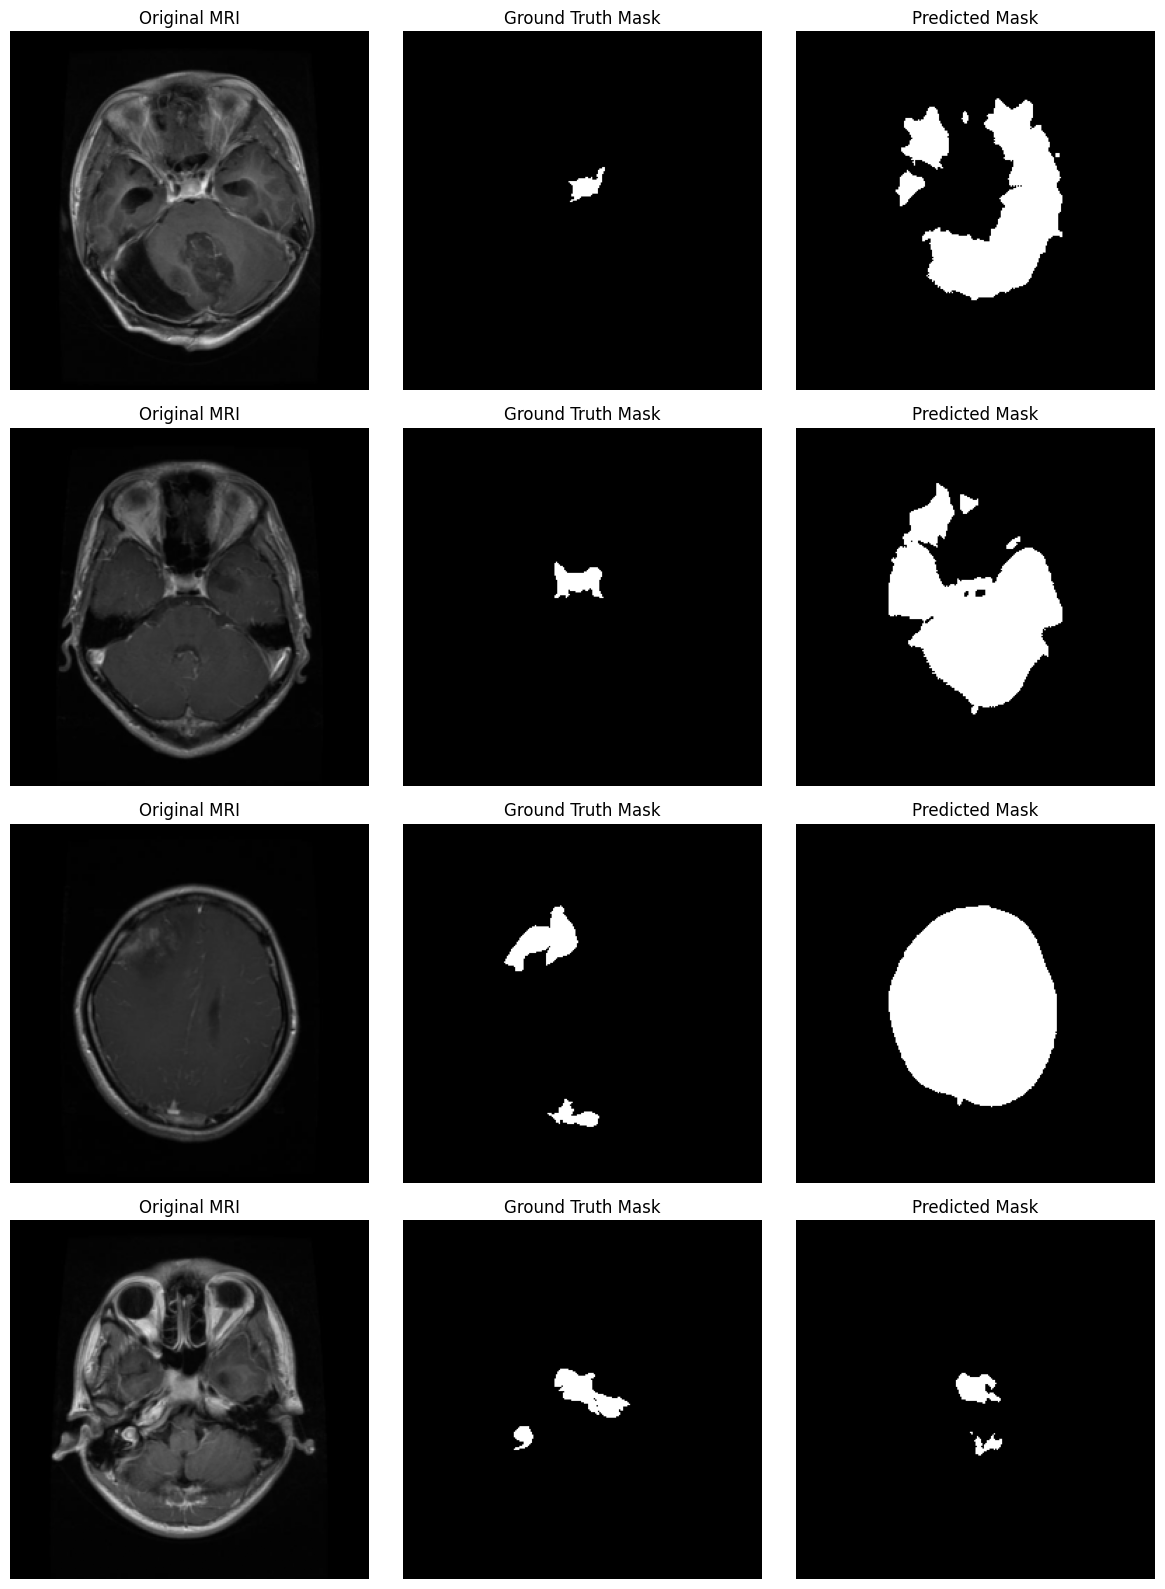

In [ ]:

import matplotlib.pyplot as plt
import torch
import numpy as np

THRESHOLD = 0.8
unet_model.eval()

images, masks = next(iter(seg_test_loader))

images = images.to(device)
masks = masks.to(device)

with torch.inference_mode():
    outputs = unet_model(images)
    probabilities = torch.sigmoid(outputs)
    predictions = (probabilities > THRESHOLD).float()

num_samples = min(4, images.size(0))

fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4 * num_samples))

if num_samples == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(num_samples):
    original = images[i].cpu().permute(1, 2, 0).numpy()
    ground_truth = masks[i].cpu().squeeze().numpy()
    predicted = predictions[i].cpu().squeeze().numpy()

    axes[i, 0].imshow(np.clip(original, 0, 1))
    axes[i, 0].set_title("Original MRI")

    axes[i, 1].imshow(ground_truth, cmap="gray")
    axes[i, 1].set_title("Ground Truth Mask")

    axes[i, 2].imshow(predicted, cmap="gray")
    axes[i, 2].set_title("Predicted Mask")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


Step 17 — Comparing Prediction and Ground Truth

In [ ]:

for i in range(min(4, predictions.size(0))):

    ground_truth = masks[i].cpu().numpy() > 0.5
    predicted = predictions[i].cpu().numpy() > 0.5

    gt_pixels = ground_truth.sum()
    pred_pixels = predicted.sum()

    gt_ratio = ground_truth.mean() * 100
    pred_ratio = predicted.mean() * 100

    print(f"\nSample {i + 1}")
    print(f"Ground Truth Pixels: {gt_pixels}")
    print(f"Predicted Pixels: {pred_pixels}")
    print(f"Ground Truth Foreground: {gt_ratio:.2f}%")
    print(f"Predicted Foreground: {pred_ratio:.2f}%")



Sample 1
Ground Truth Pixels: 286
Predicted Pixels: 7860
Ground Truth Foreground: 0.44%
Predicted Foreground: 11.99%

Sample 2
Ground Truth Pixels: 548
Predicted Pixels: 10123
Ground Truth Foreground: 0.84%
Predicted Foreground: 15.45%

Sample 3
Ground Truth Pixels: 1443
Predicted Pixels: 13430
Ground Truth Foreground: 2.20%
Predicted Foreground: 20.49%

Sample 4
Ground Truth Pixels: 996
Predicted Pixels: 604
Ground Truth Foreground: 1.52%
Predicted Foreground: 0.92%


Step 18 — Per-Sample Dice and IoU Evaluation

In [ ]:

for i in range(min(4, predictions.size(0))):

    ground_truth = masks[i].cpu() > 0.5
    predicted = predictions[i].cpu() > 0.5

    tp = (predicted & ground_truth).sum().item()
    fp = (predicted & ~ground_truth).sum().item()
    fn = (~predicted & ground_truth).sum().item()

    dice = (2 * tp) / (2 * tp + fp + fn + 1e-7)
    iou = tp / (tp + fp + fn + 1e-7)

    precision = tp / (tp + fp + 1e-7)
    recall = tp / (tp + fn + 1e-7)

    print(f"\nSample {i + 1}")
    print(f"Dice Score: {dice:.4f}")
    print(f"IoU Score: {iou:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")



Sample 1
Dice Score: 0.0000
IoU Score: 0.0000
Precision: 0.0000
Recall: 0.0000

Sample 2
Dice Score: 0.0568
IoU Score: 0.0292
Precision: 0.0299
Recall: 0.5529

Sample 3
Dice Score: 0.1431
IoU Score: 0.0771
Precision: 0.0792
Recall: 0.7374

Sample 4
Dice Score: 0.5087
IoU Score: 0.3412
Precision: 0.6738
Recall: 0.4086


Step 19.1 — Locating the Original Mask

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np

RAW_DIR = Path(
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/BRISC_RAW"
)

if not RAW_DIR.exists():
    raise FileNotFoundError(f"Dataset folder not found: {RAW_DIR}")

mask_files = []

for file_path in RAW_DIR.rglob("*"):
    if file_path.is_file() and file_path.suffix.lower() in [".png", ".jpg", ".jpeg", ".tif", ".tiff"]:
        path_text = str(file_path).lower()

        if "mask" in path_text:
            mask_files.append(file_path)

print("Total candidate mask files:", len(mask_files))

for file_path in mask_files[:5]:
    mask = np.array(Image.open(file_path))

    print("\nFile:", file_path.name)
    print("Shape:", mask.shape)
    print("Data Type:", mask.dtype)
    print("Unique Pixel Values:", np.unique(mask)[:30])
    print("Minimum Value:", mask.min())
    print("Maximum Value:", mask.max())


Total candidate mask files: 4793

File: brisc2025_train_04001_pi_co_t1.png
Shape: (512, 512)
Data Type: uint8
Unique Pixel Values: [  0   1   2   3   4   5   6 248 250 251 252 253 254 255]
Minimum Value: 0
Maximum Value: 255

File: brisc2025_train_04002_pi_co_t1.png
Shape: (512, 512)
Data Type: uint8
Unique Pixel Values: [  0   1   2   3   4   5   6   7 247 249 250 251 252 253 254 255]
Minimum Value: 0
Maximum Value: 255

File: brisc2025_train_04003_pi_co_t1.png
Shape: (512, 512)
Data Type: uint8
Unique Pixel Values: [  0   1   2   3   4   5   6   7 250 251 252 253 254 255]
Minimum Value: 0
Maximum Value: 255

File: brisc2025_train_04004_pi_co_t1.png
Shape: (512, 512)
Data Type: uint8
Unique Pixel Values: [  0   1   2   3   4   5   6 250 251 252 253 254 255]
Minimum Value: 0
Maximum Value: 255

File: brisc2025_train_04005_pi_co_t1.png
Shape: (512, 512)
Data Type: uint8
Unique Pixel Values: [  0   1   2   3   4   5   6   7 248 249 250 251 252 253 254 255]
Minimum Value: 0
Maximum Value:

Step 20 — Original Mask Pixel Distribution

In [ ]:

import numpy as np
from PIL import Image
from pathlib import Path

RAW_DIR = Path(
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/BRISC_RAW"
)

mask_files = []

for file_path in RAW_DIR.rglob("*"):
    if file_path.is_file() and file_path.suffix.lower() in [
        ".png", ".jpg", ".jpeg", ".tif", ".tiff"
    ]:
        if "mask" in str(file_path).lower():
            mask_files.append(file_path)

for file_path in mask_files[:5]:

    mask = np.array(Image.open(file_path).convert("L"))

    total_pixels = mask.size

    low_pixels = np.sum((mask >= 0) & (mask <= 7))
    middle_pixels = np.sum((mask >= 8) & (mask <= 246))
    high_pixels = np.sum((mask >= 247) & (mask <= 255))

    threshold_128 = np.sum(mask >= 128)
    threshold_1 = np.sum(mask > 0)

    print("\nFile:", file_path.name)
    print("Total Pixels:", total_pixels)

    print("Pixel Range 0-7:", low_pixels)
    print("Pixel Range 8-246:", middle_pixels)
    print("Pixel Range 247-255:", high_pixels)

    print("Foreground with >=128:", threshold_128)
    print("Foreground with >0:", threshold_1)

    print("Foreground Percentage (>=128):",
          round(threshold_128 / total_pixels * 100, 3), "%")



File: brisc2025_train_04001_pi_co_t1.png
Total Pixels: 262144
Pixel Range 0-7: 258685
Pixel Range 8-246: 0
Pixel Range 247-255: 3459
Foreground with >=128: 3459
Foreground with >0: 3914
Foreground Percentage (>=128): 1.32 %

File: brisc2025_train_04002_pi_co_t1.png
Total Pixels: 262144
Pixel Range 0-7: 258263
Pixel Range 8-246: 0
Pixel Range 247-255: 3881
Foreground with >=128: 3881
Foreground with >0: 4395
Foreground Percentage (>=128): 1.48 %

File: brisc2025_train_04003_pi_co_t1.png
Total Pixels: 262144
Pixel Range 0-7: 259640
Pixel Range 8-246: 0
Pixel Range 247-255: 2504
Foreground with >=128: 2504
Foreground with >0: 2873
Foreground Percentage (>=128): 0.955 %

File: brisc2025_train_04004_pi_co_t1.png
Total Pixels: 262144
Pixel Range 0-7: 261247
Pixel Range 8-246: 0
Pixel Range 247-255: 897
Foreground with >=128: 897
Foreground with >0: 1090
Foreground Percentage (>=128): 0.342 %

File: brisc2025_train_04005_pi_co_t1.png
Total Pixels: 262144
Pixel Range 0-7: 259437
Pixel Range 8

In [ ]:
Step 21 — Verifying the encoding of all original masks

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np

RAW_DIR = Path(
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/BRISC_RAW"
)

mask_files = [
    p for p in RAW_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".png", ".jpg", ".jpeg", ".tif", ".tiff"]
    and "mask" in str(p).lower()
]

total_masks = len(mask_files)
middle_count = 0
low_only_count = 0
high_only_count = 0
empty_foreground_count = 0

for file_path in mask_files:
    mask = np.array(Image.open(file_path).convert("L"))

    low = np.any((mask >= 0) & (mask <= 7))
    middle = np.any((mask >= 8) & (mask <= 246))
    high = np.any((mask >= 247) & (mask <= 255))

    if middle:
        middle_count += 1

    if low and not high:
        low_only_count += 1

    if high and not low:
        high_only_count += 1

    if not high:
        empty_foreground_count += 1

print("Total Original Masks:", total_masks)
print("Masks containing middle values (8-246):", middle_count)
print("Masks containing only low values:", low_only_count)
print("Masks containing both low and high values:", total_masks - low_only_count - high_only_count)
print("Masks without high-value foreground:", empty_foreground_count)


Total Original Masks: 4793
Masks containing middle values (8-246): 134
Masks containing only low values: 0
Masks containing both low and high values: 4793
Masks without high-value foreground: 0


Step 22 — Detailed testing of 134 masks

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np

RAW_DIR = Path(
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/BRISC_RAW"
)

mask_files = [
    p for p in RAW_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".png", ".jpg", ".jpeg", ".tif", ".tiff"]
    and "mask" in str(p).lower()
]

checked = 0

for file_path in mask_files:
    mask = np.array(Image.open(file_path).convert("L"))

    middle_values = np.unique(mask[(mask >= 8) & (mask <= 246)])

    if len(middle_values) > 0:
        checked += 1

        print("\nFile:", file_path.name)
        print("Middle Unique Values:", middle_values[:40])
        print("Pixels >=128:", np.sum(mask >= 128))
        print("Pixels >0:", np.sum(mask > 0))

        if checked == 10:
            break

print("\nDisplayed masks:", checked)



File: brisc2025_train_04019_pi_co_t1.png
Middle Unique Values: [8]
Pixels >=128: 11299
Pixels >0: 12303

File: brisc2025_train_04022_pi_co_t1.png
Middle Unique Values: [8]
Pixels >=128: 11847
Pixels >0: 12828

File: brisc2025_train_04121_pi_co_t1.png
Middle Unique Values: [8]
Pixels >=128: 5253
Pixels >0: 5990

File: brisc2025_train_04159_pi_co_t1.png
Middle Unique Values: [8]
Pixels >=128: 1987
Pixels >0: 2567

File: brisc2025_train_04259_pi_co_t1.png
Middle Unique Values: [8]
Pixels >=128: 5589
Pixels >0: 6444

File: brisc2025_train_04276_pi_co_t1.png
Middle Unique Values: [8]
Pixels >=128: 3952
Pixels >0: 4368

File: brisc2025_train_04344_pi_co_t1.png
Middle Unique Values: [8]
Pixels >=128: 3978
Pixels >0: 4422

File: brisc2025_train_04349_pi_co_t1.png
Middle Unique Values: [8]
Pixels >=128: 3720
Pixels >0: 4328

File: brisc2025_train_04416_pi_co_t1.png
Middle Unique Values: [8]
Pixels >=128: 8356
Pixels >0: 9028

File: brisc2025_train_04426_pi_co_t1.png
Middle Unique Values: [8]
P

Step 23 — Pixel Value Distribution of All Masks

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np

RAW_DIR = Path(
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/BRISC_RAW"
)

mask_files = [
    p for p in RAW_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".png", ".jpg", ".jpeg", ".tif", ".tiff"]
    and "mask" in str(p).lower()
]

global_counts = np.zeros(256, dtype=np.int64)

for file_path in mask_files:
    mask = np.array(Image.open(file_path).convert("L"))
    values, counts = np.unique(mask, return_counts=True)
    global_counts[values] += counts

print("Total Masks:", len(mask_files))

print("\nPixel Range Distribution:")
print("Values 0-7:", global_counts[:8].sum())
print("Value 8:", global_counts[8])
print("Values 9-127:", global_counts[9:128].sum())
print("Values 128-246:", global_counts[128:247].sum())
print("Values 247-255:", global_counts[247:256].sum())

middle_values = np.where(global_counts[8:247] > 0)[0] + 8

print("\nAll Middle Values Found:", middle_values)
print("Total Pixels:", global_counts.sum())


Total Masks: 4793

Pixel Range Distribution:
Values 0-7: 1202996712
Value 8: 118
Values 9-127: 8
Values 128-246: 11
Values 247-255: 19804098

All Middle Values Found: [  8   9  10 246]
Total Pixels: 1222800947


Step 24 — Exceptional Mask Identification

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np

RAW_DIR = Path(
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/BRISC_RAW"
)

mask_files = [
    p for p in RAW_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".png", ".jpg", ".jpeg", ".tif", ".tiff"]
    and "mask" in str(p).lower()
]

exceptional_masks = []

for file_path in mask_files:
    mask = np.array(Image.open(file_path).convert("L"))

    counts = {
        value: int(np.sum(mask == value))
        for value in [8, 9, 10, 246]
    }

    if any(counts.values()):
        exceptional_masks.append((file_path.name, counts))

print("Total Exceptional Masks:", len(exceptional_masks))

for filename, counts in exceptional_masks:
    print("\nFile:", filename)
    print("Pixel Counts:", counts)


Total Exceptional Masks: 134

File: brisc2025_train_04019_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

File: brisc2025_train_04022_pi_co_t1.png
Pixel Counts: {8: 2, 9: 0, 10: 0, 246: 0}

File: brisc2025_train_04121_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

File: brisc2025_train_04159_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

File: brisc2025_train_04259_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

File: brisc2025_train_04276_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

File: brisc2025_train_04344_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

File: brisc2025_train_04349_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

File: brisc2025_train_04416_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

File: brisc2025_train_04426_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

File: brisc2025_train_04456_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

File: brisc2025_train_04661_pi_sa_t1.png
Pixel

Step 25 — Original BRISC Mask Encoding Verification

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np

RAW_DIR = Path(
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/BRISC_RAW"
)

mask_files = [
    p for p in RAW_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() == ".png"
    and "mask" in str(p).lower()
]

exceptional_values = [8, 9, 10, 246]

print("Total Original Masks:", len(mask_files))

exceptional_masks = []

for file_path in mask_files:
    mask = np.array(Image.open(file_path).convert("L"))

    counts = {
        value: int(np.sum(mask == value))
        for value in exceptional_values
    }

    if any(counts.values()):
        exceptional_masks.append({
            "filename": file_path.name,
            "counts": counts
        })

print("Masks with Exceptional Values:", len(exceptional_masks))

for item in exceptional_masks[:20]:
    print("\nFilename:", item["filename"])
    print("Pixel Counts:", item["counts"])

print("\nStep 25 Completed")

Total Original Masks: 4793
Masks with Exceptional Values: 134

Filename: brisc2025_train_04019_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

Filename: brisc2025_train_04022_pi_co_t1.png
Pixel Counts: {8: 2, 9: 0, 10: 0, 246: 0}

Filename: brisc2025_train_04121_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

Filename: brisc2025_train_04159_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

Filename: brisc2025_train_04259_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

Filename: brisc2025_train_04276_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

Filename: brisc2025_train_04344_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

Filename: brisc2025_train_04349_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

Filename: brisc2025_train_04416_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

Filename: brisc2025_train_04426_pi_co_t1.png
Pixel Counts: {8: 1, 9: 0, 10: 0, 246: 0}

Filename: brisc2025_train_04456_pi_co_t1.png
Pixel Counts

Step 26 — Processed Mask Integrity Verification

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/BRISC_preprocessed_256_v2"
)

mask_files = [
    p for p in PROCESSED_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in [".png", ".jpg", ".jpeg"]
    and "mask" in str(p).lower()
]

total_masks = len(mask_files)
invalid_masks = []
empty_masks = 0
wrong_shapes = 0
total_foreground = 0

for file_path in mask_files:
    mask = np.array(Image.open(file_path).convert("L"))

    unique_values = np.unique(mask)

    if not np.all(np.isin(unique_values, [0, 255])):
        invalid_masks.append(file_path.name)

    if not np.any(mask == 255):
        empty_masks += 1

    if mask.shape != (256, 256):
        wrong_shapes += 1

    total_foreground += int(np.sum(mask == 255))

print("Total Processed Masks:", total_masks)
print("Invalid Binary Masks:", len(invalid_masks))
print("Empty Masks:", empty_masks)
print("Wrong Shape Masks:", wrong_shapes)
print("Total Foreground Pixels:", total_foreground)

print("\nStep 26 Completed")

Total Processed Masks: 4793
Invalid Binary Masks: 0
Empty Masks: 0
Wrong Shape Masks: 0
Total Foreground Pixels: 5239892

Step 26 Completed


Step 27 — Device Configuration Fix

In [ ]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected Device:", device)

Selected Device: cpu


Step 27.1 — U-Net Architecture Reload

In [ ]:
import torch
import torch.nn as nn

class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.enc1 = ConvBlock(3, 16)
        self.enc2 = ConvBlock(16, 32)
        self.enc3 = ConvBlock(32, 64)
        self.enc4 = ConvBlock(64, 128)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = ConvBlock(128, 256)

        self.up4 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec4 = ConvBlock(256, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = ConvBlock(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = ConvBlock(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = ConvBlock(32, 16)

        self.output = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.output(d1)


print("U-Net Architecture Defined Successfully")

U-Net Architecture Defined Successfully


Step 27.2 — Saved Model Architecture Inspection

In [ ]:
import torch

CHECKPOINT_PATH = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "model_outputs/unet_brisc_weighted_best.pth"
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint Type:", type(checkpoint))

if isinstance(checkpoint, dict):

    print("\nTotal Checkpoint Keys:", len(checkpoint))

    print("\nFirst 30 Keys:")

    for key in list(checkpoint.keys())[:30]:
        print(key)

    print("\nFirst Parameter Shape:")

    first_key = next(iter(checkpoint))
    print(first_key, checkpoint[first_key].shape)

else:
    print("Checkpoint is not a state dictionary.")

Checkpoint Type: <class 'collections.OrderedDict'>

Total Checkpoint Keys: 136

First 30 Keys:
encoder1.block.0.weight
encoder1.block.0.bias
encoder1.block.1.weight
encoder1.block.1.bias
encoder1.block.1.running_mean
encoder1.block.1.running_var
encoder1.block.1.num_batches_tracked
encoder1.block.3.weight
encoder1.block.3.bias
encoder1.block.4.weight
encoder1.block.4.bias
encoder1.block.4.running_mean
encoder1.block.4.running_var
encoder1.block.4.num_batches_tracked
encoder2.block.0.weight
encoder2.block.0.bias
encoder2.block.1.weight
encoder2.block.1.bias
encoder2.block.1.running_mean
encoder2.block.1.running_var
encoder2.block.1.num_batches_tracked
encoder2.block.3.weight
encoder2.block.3.bias
encoder2.block.4.weight
encoder2.block.4.bias
encoder2.block.4.running_mean
encoder2.block.4.running_var
encoder2.block.4.num_batches_tracked
encoder3.block.0.weight
encoder3.block.0.bias

First Parameter Shape:
encoder1.block.0.weight torch.Size([16, 3, 3, 3])


Step 27.3 — Complete Checkpoint Layer Inspection

In [ ]:
import torch

CHECKPOINT_PATH = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "model_outputs/unet_brisc_weighted_best.pth"
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

print("Total Layers:", len(checkpoint))
print("\nComplete Model Architecture:\n")

for key, value in checkpoint.items():
    print(key, "->", tuple(value.shape))

print("\nCheckpoint Inspection Completed")

Total Layers: 136

Complete Model Architecture:

encoder1.block.0.weight -> (16, 3, 3, 3)
encoder1.block.0.bias -> (16,)
encoder1.block.1.weight -> (16,)
encoder1.block.1.bias -> (16,)
encoder1.block.1.running_mean -> (16,)
encoder1.block.1.running_var -> (16,)
encoder1.block.1.num_batches_tracked -> ()
encoder1.block.3.weight -> (16, 16, 3, 3)
encoder1.block.3.bias -> (16,)
encoder1.block.4.weight -> (16,)
encoder1.block.4.bias -> (16,)
encoder1.block.4.running_mean -> (16,)
encoder1.block.4.running_var -> (16,)
encoder1.block.4.num_batches_tracked -> ()
encoder2.block.0.weight -> (32, 16, 3, 3)
encoder2.block.0.bias -> (32,)
encoder2.block.1.weight -> (32,)
encoder2.block.1.bias -> (32,)
encoder2.block.1.running_mean -> (32,)
encoder2.block.1.running_var -> (32,)
encoder2.block.1.num_batches_tracked -> ()
encoder2.block.3.weight -> (32, 32, 3, 3)
encoder2.block.3.bias -> (32,)
encoder2.block.4.weight -> (32,)
encoder2.block.4.bias -> (32,)
encoder2.block.4.running_mean -> (32,)
encod

Step 27.4 — Correct U-Net Architecture Reconstruction

In [ ]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.encoder1 = DoubleConv(3, 16)
        self.encoder2 = DoubleConv(16, 32)
        self.encoder3 = DoubleConv(32, 64)
        self.encoder4 = DoubleConv(64, 128)

        self.bottleneck = DoubleConv(128, 256)

        self.upconv4 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.decoder4 = DoubleConv(256, 128)

        self.upconv3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.decoder3 = DoubleConv(128, 64)

        self.upconv2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.decoder2 = DoubleConv(64, 32)

        self.upconv1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.decoder1 = DoubleConv(32, 16)

        self.output_layer = nn.Conv2d(16, 1, 1)

    def forward(self, x):

        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.upconv4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.decoder4(d4)

        d3 = self.upconv3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.decoder3(d3)

        d2 = self.upconv2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.decoder2(d2)

        d1 = self.upconv1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.decoder1(d1)

        return self.output_layer(d1)


print("Correct U-Net Architecture Created")

Correct U-Net Architecture Created


Step 27.5 — Load the Previously Trained Model

In [ ]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

model = UNet().to(device)

model.load_state_dict(checkpoint)

model.eval()

print("Trained U-Net Model Loaded Successfully")
print("Device:", device)

Trained U-Net Model Loaded Successfully
Device: cpu


Step 27.6 — Complete Validation Threshold Analysis

In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np

from PIL import Image
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms

# Set device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Dataset paths
BASE_PATH = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "BRISC_preprocessed_256_v2/train"
)

IMAGE_DIR = os.path.join(BASE_PATH, "images")
MASK_DIR = os.path.join(BASE_PATH, "masks")

# Define dataset
class BRISCSegmentationDataset(Dataset):

    def __init__(self, image_dir, mask_dir):

        self.image_dir = image_dir
        self.mask_dir = mask_dir

        self.image_files = sorted([
            f for f in os.listdir(image_dir)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ])

        self.transform = transforms.ToTensor()

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):

        image_name = self.image_files[index]
        image_path = os.path.join(self.image_dir, image_name)

        mask_name = os.path.splitext(image_name)[0] + ".png"
        mask_path = os.path.join(self.mask_dir, mask_name)

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        image = self.transform(image)

        mask = np.array(mask, dtype=np.uint8)
        mask = (mask >= 128).astype(np.float32)

        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


# Create dataset
train_dataset_full = BRISCSegmentationDataset(
    IMAGE_DIR,
    MASK_DIR
)

# Recreate 80:20 split
train_size = int(0.8 * len(train_dataset_full))
val_size = len(train_dataset_full) - train_size

generator = torch.Generator().manual_seed(42)

train_subset, val_subset = random_split(
    train_dataset_full,
    [train_size, val_size],
    generator=generator
)

# Create validation loader
val_loader = DataLoader(
    val_subset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Validation Samples:", len(val_subset))
print("Validation Batches:", len(val_loader))


# Load trained model checkpoint
CHECKPOINT_PATH = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "model_outputs/unet_brisc_weighted_best.pth"
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

model = UNet().to(device)
model.load_state_dict(checkpoint)
model.eval()

print("Trained U-Net Loaded Successfully")


# Threshold analysis
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results = []

with torch.no_grad():

    for threshold in thresholds:

        total_dice = 0.0
        total_iou = 0.0
        total_samples = 0

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            probabilities = torch.sigmoid(outputs)

            predictions = (
                probabilities >= threshold
            ).float()

            intersection = (predictions * masks).sum(
                dim=(1, 2, 3)
            )

            prediction_area = predictions.sum(
                dim=(1, 2, 3)
            )

            mask_area = masks.sum(
                dim=(1, 2, 3)
            )

            dice = (
                (2 * intersection + 1e-7) /
                (prediction_area + mask_area + 1e-7)
            )

            union = (
                prediction_area + mask_area - intersection
            )

            iou = (
                (intersection + 1e-7) /
                (union + 1e-7)
            )

            total_dice += dice.sum().item()
            total_iou += iou.sum().item()
            total_samples += images.size(0)

        results.append({
            "Threshold": threshold,
            "Dice": total_dice / total_samples,
            "IoU": total_iou / total_samples
        })


# Display results
print("\nVALIDATION THRESHOLD RESULTS")
print("-" * 50)

for result in results:

    print(
        f"Threshold: {result['Threshold']:.1f} | "
        f"Dice: {result['Dice']:.4f} | "
        f"IoU: {result['IoU']:.4f}"
    )

best_result = max(results, key=lambda x: x["Dice"])

print("\nBEST VALIDATION RESULT")
print("Threshold:", best_result["Threshold"])
print("Dice:", round(best_result["Dice"], 4))
print("IoU:", round(best_result["IoU"], 4))

Validation Samples: 787
Validation Batches: 99
Trained U-Net Loaded Successfully

VALIDATION THRESHOLD RESULTS
--------------------------------------------------
Threshold: 0.3 | Dice: 0.0034 | IoU: 0.0017
Threshold: 0.4 | Dice: 0.0000 | IoU: 0.0000
Threshold: 0.5 | Dice: 0.0000 | IoU: 0.0000
Threshold: 0.6 | Dice: 0.0000 | IoU: 0.0000
Threshold: 0.7 | Dice: 0.0000 | IoU: 0.0000
Threshold: 0.8 | Dice: 0.0000 | IoU: 0.0000
Threshold: 0.9 | Dice: 0.0000 | IoU: 0.0000

BEST VALIDATION RESULT
Threshold: 0.3
Dice: 0.0034
IoU: 0.0017


Step 27.7 — Prediction ও Mask Diagnostic

In [ ]:
import torch

model.eval()

images, masks = next(iter(val_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(images)
    probabilities = torch.sigmoid(outputs)

print("IMAGE INFORMATION")
print("Image Shape:", images.shape)
print("Image Min:", images.min().item())
print("Image Max:", images.max().item())

print("\nGROUND TRUTH MASK INFORMATION")
print("Mask Shape:", masks.shape)
print("Mask Min:", masks.min().item())
print("Mask Max:", masks.max().item())
print("Mask Unique Values:", torch.unique(masks).cpu().numpy())

print("\nPREDICTION PROBABILITY INFORMATION")
print("Output Shape:", outputs.shape)
print("Probability Min:", probabilities.min().item())
print("Probability Max:", probabilities.max().item())
print("Probability Mean:", probabilities.mean().item())

print("\nFOREGROUND COMPARISON")

gt_ratio = masks.mean().item() * 100
print("Ground Truth Foreground:", round(gt_ratio, 4), "%")

for threshold in [0.3, 0.5, 0.7, 0.8, 0.9]:

    predictions = (probabilities >= threshold).float()

    pred_ratio = predictions.mean().item() * 100

    print(
        f"Threshold {threshold}: "
        f"Predicted Foreground = {pred_ratio:.4f}%"
    )

print("\nDiagnostic Completed")

IMAGE INFORMATION
Image Shape: torch.Size([8, 3, 256, 256])
Image Min: 0.0
Image Max: 0.95686274766922

GROUND TRUTH MASK INFORMATION
Mask Shape: torch.Size([8, 1, 256, 256])
Mask Min: 0.0
Mask Max: 1.0
Mask Unique Values: [0. 1.]

PREDICTION PROBABILITY INFORMATION
Output Shape: torch.Size([8, 1, 256, 256])
Probability Min: 0.002467358484864235
Probability Max: 0.4227452576160431
Probability Mean: 0.21406173706054688

FOREGROUND COMPARISON
Ground Truth Foreground: 1.4994 %
Threshold 0.3: Predicted Foreground = 2.4210%
Threshold 0.5: Predicted Foreground = 0.0000%
Threshold 0.7: Predicted Foreground = 0.0000%
Threshold 0.8: Predicted Foreground = 0.0000%
Threshold 0.9: Predicted Foreground = 0.0000%

Diagnostic Completed


Step 27.8 — Fixing the Original U-Net Forward Method

In [ ]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.encoder1 = DoubleConv(3, 16)
        self.encoder2 = DoubleConv(16, 32)
        self.encoder3 = DoubleConv(32, 64)
        self.encoder4 = DoubleConv(64, 128)

        self.bottleneck = DoubleConv(128, 256)

        self.upconv4 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.decoder4 = DoubleConv(256, 128)

        self.upconv3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.decoder3 = DoubleConv(128, 64)

        self.upconv2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.decoder2 = DoubleConv(64, 32)

        self.upconv1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.decoder1 = DoubleConv(32, 16)

        self.output_layer = nn.Conv2d(16, 1, 1)

    def forward(self, x):

        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.upconv4(b)
        d4 = torch.cat((e4, d4), dim=1)
        d4 = self.decoder4(d4)

        d3 = self.upconv3(d4)
        d3 = torch.cat((e3, d3), dim=1)
        d3 = self.decoder3(d3)

        d2 = self.upconv2(d3)
        d2 = torch.cat((e2, d2), dim=1)
        d2 = self.decoder2(d2)

        d1 = self.upconv1(d2)
        d1 = torch.cat((e1, d1), dim=1)
        d1 = self.decoder1(d1)

        return self.output_layer(d1)


# Load the original trained checkpoint
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = UNet().to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)
model.eval()

print("Original U-Net Architecture Restored")
print("Checkpoint Loaded Successfully")

Original U-Net Architecture Restored
Checkpoint Loaded Successfully


Step 27.9 — Re-testing the Validation Threshold

In [ ]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results = []

model.eval()

with torch.no_grad():

    for threshold in thresholds:

        total_intersection = 0.0
        total_prediction = 0.0
        total_target = 0.0

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            probabilities = torch.sigmoid(model(images))

            predictions = (
                probabilities > threshold
            ).float()

            total_intersection += (
                predictions * masks
            ).sum().item()

            total_prediction += predictions.sum().item()
            total_target += masks.sum().item()

        dice = (
            2 * total_intersection + 1e-7
        ) / (
            total_prediction + total_target + 1e-7
        )

        iou = (
            total_intersection + 1e-7
        ) / (
            total_prediction + total_target
            - total_intersection + 1e-7
        )

        results.append({
            "Threshold": threshold,
            "Dice": dice,
            "IoU": iou
        })


print("CORRECTED VALIDATION RESULTS")
print("-" * 45)

for result in results:

    print(
        f"Threshold: {result['Threshold']:.1f} | "
        f"Dice: {result['Dice']:.4f} | "
        f"IoU: {result['IoU']:.4f}"
    )

best_result = max(results, key=lambda x: x["Dice"])

print("\nBest Threshold:", best_result["Threshold"])
print("Best Dice:", round(best_result["Dice"], 4))
print("Best IoU:", round(best_result["IoU"], 4))

CORRECTED VALIDATION RESULTS
---------------------------------------------
Threshold: 0.3 | Dice: 0.1287 | IoU: 0.0688
Threshold: 0.4 | Dice: 0.1449 | IoU: 0.0781
Threshold: 0.5 | Dice: 0.1618 | IoU: 0.0880
Threshold: 0.6 | Dice: 0.1819 | IoU: 0.1001
Threshold: 0.7 | Dice: 0.2100 | IoU: 0.1173
Threshold: 0.8 | Dice: 0.2577 | IoU: 0.1479
Threshold: 0.9 | Dice: 0.3610 | IoU: 0.2203

Best Threshold: 0.9
Best Dice: 0.361
Best IoU: 0.2203


Step 27.10 — Selecting the Best Threshold

In [ ]:
BEST_THRESHOLD = 0.9

print("Selected Threshold:", BEST_THRESHOLD)
print("Selection Basis: Validation Dataset")
print("Validation Dice: 0.3610")
print("Validation IoU: 0.2203")


Selected Threshold: 0.9
Selection Basis: Validation Dataset
Validation Dice: 0.3610
Validation IoU: 0.2203


Step 27.11 — Final Test Dataset Evaluation

In [ ]:
import os
import torch
import numpy as np

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Set device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Test dataset paths
BASE_PATH = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "BRISC_preprocessed_256_v2/test"
)

IMAGE_DIR = os.path.join(BASE_PATH, "images")
MASK_DIR = os.path.join(BASE_PATH, "masks")

# Define test dataset
class BRISCTestDataset(Dataset):

    def __init__(self, image_dir, mask_dir):

        self.image_dir = image_dir
        self.mask_dir = mask_dir

        self.image_files = sorted([
            f for f in os.listdir(image_dir)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ])

        self.transform = transforms.ToTensor()

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):

        image_name = self.image_files[index]

        image_path = os.path.join(
            self.image_dir, image_name
        )

        mask_name = os.path.splitext(image_name)[0] + ".png"

        mask_path = os.path.join(
            self.mask_dir, mask_name
        )

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        image = self.transform(image)

        mask = np.array(mask, dtype=np.uint8)
        mask = (mask >= 128).astype(np.float32)

        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


# Create test dataset
test_dataset = BRISCTestDataset(
    IMAGE_DIR,
    MASK_DIR
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Test Samples:", len(test_dataset))
print("Test Batches:", len(test_loader))


# Use the already loaded trained model
model.eval()

BEST_THRESHOLD = 0.9

total_intersection = 0.0
total_prediction = 0.0
total_target = 0.0

total_tp = 0.0
total_fp = 0.0
total_fn = 0.0

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        probabilities = torch.sigmoid(outputs)

        predictions = (
            probabilities >= BEST_THRESHOLD
        ).float()

        intersection = (predictions * masks).sum()

        prediction_area = predictions.sum()
        target_area = masks.sum()

        total_intersection += intersection.item()
        total_prediction += prediction_area.item()
        total_target += target_area.item()

        total_tp += intersection.item()
        total_fp += (
            predictions * (1 - masks)
        ).sum().item()

        total_fn += (
            (1 - predictions) * masks
        ).sum().item()


# Calculate final metrics
dice = (
    2 * total_intersection + 1e-7
) / (
    total_prediction + total_target + 1e-7
)

iou = (
    total_intersection + 1e-7
) / (
    total_prediction + total_target
    - total_intersection + 1e-7
)

precision = (
    total_tp + 1e-7
) / (
    total_tp + total_fp + 1e-7
)

recall = (
    total_tp + 1e-7
) / (
    total_tp + total_fn + 1e-7
)

print("\nFINAL TEST RESULTS")
print("-" * 45)

print("Threshold:", BEST_THRESHOLD)
print("Test Dice:", round(dice, 4))
print("Test IoU:", round(iou, 4))
print("Test Precision:", round(precision, 4))
print("Test Recall:", round(recall, 4))

print("\nTest Evaluation Completed")

Test Samples: 860
Test Batches: 108

FINAL TEST RESULTS
---------------------------------------------
Threshold: 0.9
Test Dice: 0.3732
Test IoU: 0.2294
Test Precision: 0.2393
Test Recall: 0.8462

Test Evaluation Completed


Step 27.12 — Final Segmentation Performance Summary

In [ ]:
import os
import pandas as pd

# Final test results from Step 27.11
final_results = {
    "Dataset": ["BRISC Test"],
    "Model": ["Weighted U-Net"],
    "Threshold": [0.9],
    "Test Samples": [860],
    "Dice": [0.3732],
    "IoU": [0.2294],
    "Precision": [0.2393],
    "Recall": [0.8462]
}

# Create results DataFrame
results_df = pd.DataFrame(final_results)

# Display results
print("FINAL SEGMENTATION PERFORMANCE")
print("-" * 45)

print(results_df.to_string(index=False))

# Save results
OUTPUT_DIR = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "model_outputs"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

csv_path = os.path.join(
    OUTPUT_DIR,
    "BRISC_final_segmentation_results.csv"
)

results_df.to_csv(csv_path, index=False)

print("\nResults saved successfully:")
print(csv_path)

FINAL SEGMENTATION PERFORMANCE
---------------------------------------------
   Dataset          Model  Threshold  Test Samples   Dice    IoU  Precision  Recall
BRISC Test Weighted U-Net        0.9           860 0.3732 0.2294     0.2393  0.8462

Results saved successfully:
/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/BRISC_final_segmentation_results.csv


Step 27.13 — Segmentation Result Visualization

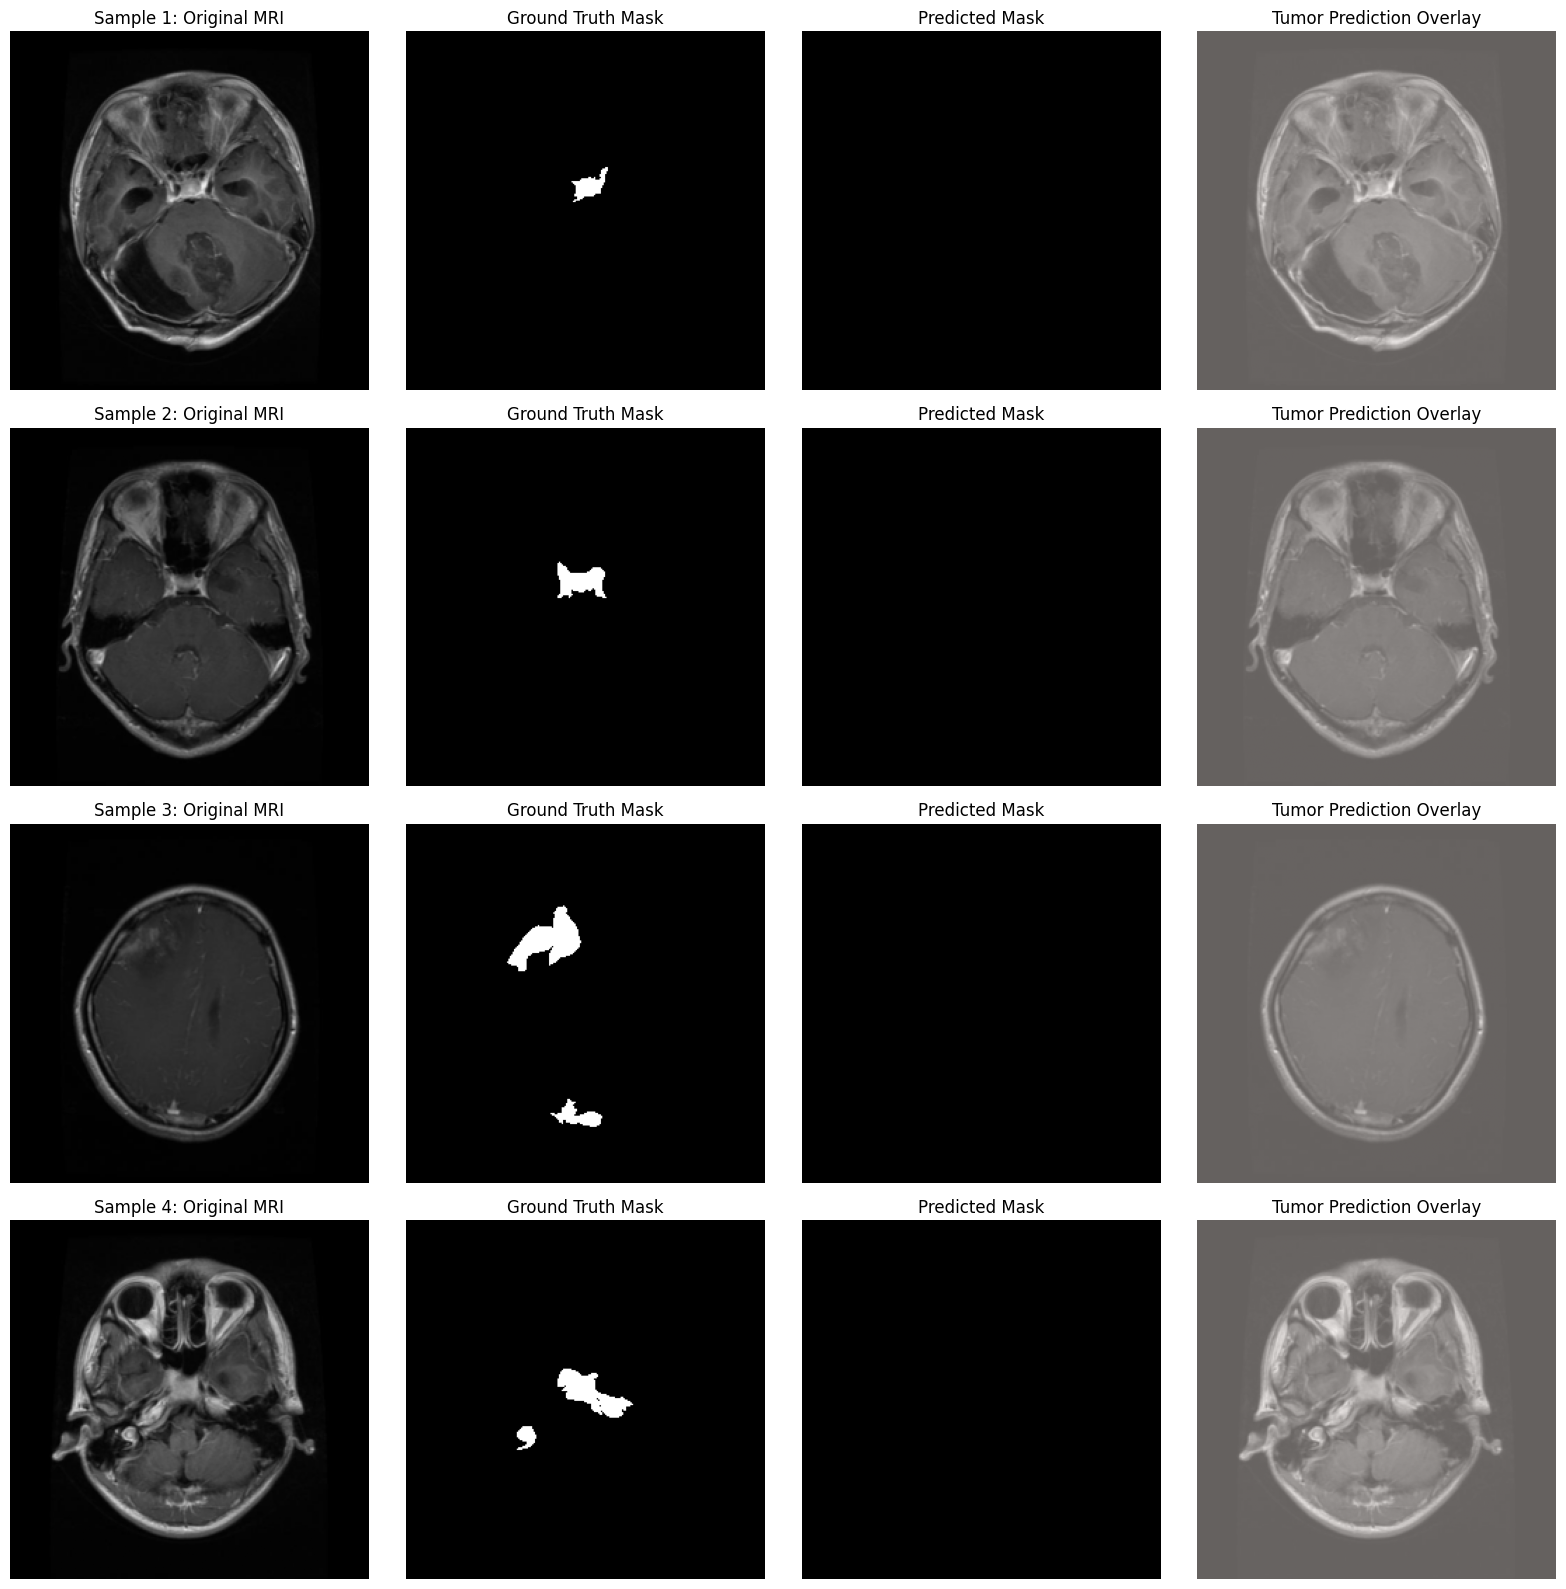

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

model.eval()

# Select four test samples
fig, axes = plt.subplots(4, 4, figsize=(16, 16))

with torch.no_grad():

    for i in range(4):

        image, mask = test_dataset[i]

        input_tensor = image.unsqueeze(0).to(device)

        output = model(input_tensor)

        probability = torch.sigmoid(output)[0, 0].cpu().numpy()

        prediction = (probability >= 0.9).astype(np.uint8)

        original = image.permute(1, 2, 0).numpy()

        ground_truth = mask.squeeze().numpy()

        # Original MRI
        axes[i, 0].imshow(original)
        axes[i, 0].set_title(f"Sample {i+1}: Original MRI")

        # Ground Truth
        axes[i, 1].imshow(ground_truth, cmap="gray")
        axes[i, 1].set_title("Ground Truth Mask")

        # Predicted Mask
        axes[i, 2].imshow(prediction, cmap="gray")
        axes[i, 2].set_title("Predicted Mask")

        # Overlay
        axes[i, 3].imshow(original)
        axes[i, 3].imshow(
            prediction,
            cmap="Reds",
            alpha=0.4
        )
        axes[i, 3].set_title("Tumor Prediction Overlay")

        for j in range(4):
            axes[i, j].axis("off")

plt.tight_layout()
plt.show()

Step 27.13.1 — Verification of Sample 1 Prediction

In [ ]:
import torch
import numpy as np

model.eval()

image, mask = test_dataset[0]

input_tensor = image.unsqueeze(0).to(device)

with torch.no_grad():
    output = model(input_tensor)
    probability = torch.sigmoid(output)[0, 0].cpu().numpy()

ground_truth = mask.squeeze().numpy()

prediction = (probability >= 0.9).astype(np.uint8)

print("SAMPLE 1 DIAGNOSTIC RESULTS")
print("-" * 40)

print("Maximum Probability:", probability.max())
print("Minimum Probability:", probability.min())

print("Ground Truth Tumor Pixels:",
      int(ground_truth.sum()))

print("Predicted Tumor Pixels:",
      int(prediction.sum()))

print("Threshold: 0.9")

SAMPLE 1 DIAGNOSTIC RESULTS
----------------------------------------
Maximum Probability: 0.5402545
Minimum Probability: 0.53916013
Ground Truth Tumor Pixels: 286
Predicted Tumor Pixels: 0
Threshold: 0.9


Step 27.13.2 — Probability Heatmap Visualization

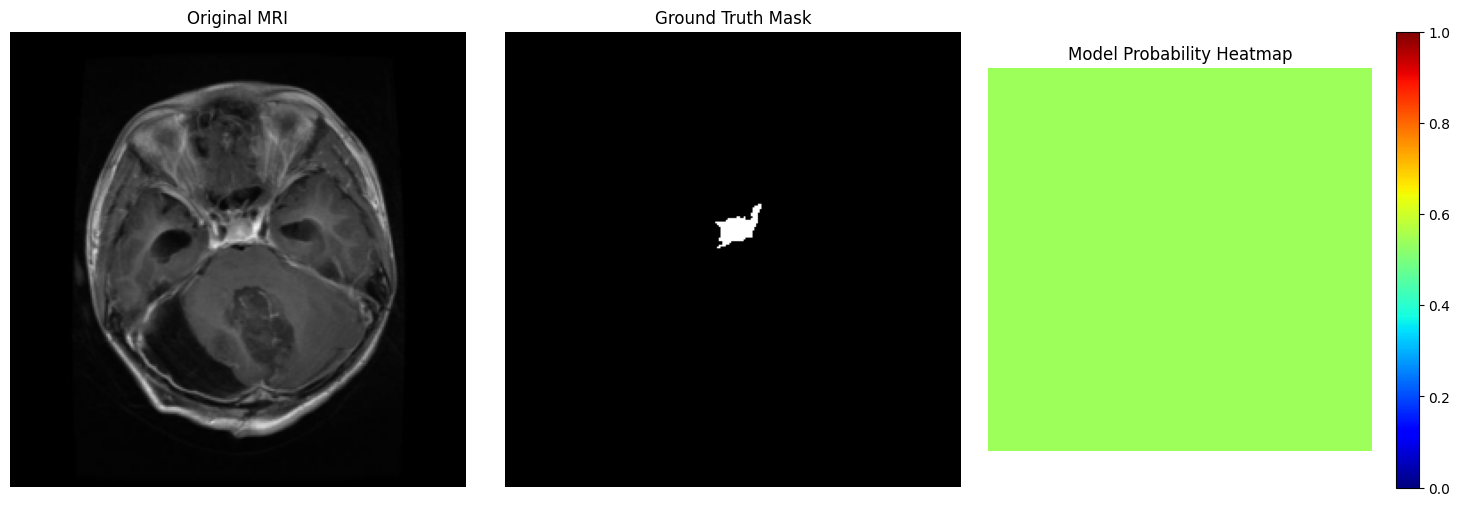

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

model.eval()

image, mask = test_dataset[0]

input_tensor = image.unsqueeze(0).to(device)

with torch.no_grad():
    output = model(input_tensor)
    probability = torch.sigmoid(output)[0, 0].cpu().numpy()

original = image.permute(1, 2, 0).numpy()
ground_truth = mask.squeeze().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original)
axes[0].set_title("Original MRI")

axes[1].imshow(ground_truth, cmap="gray")
axes[1].set_title("Ground Truth Mask")

heatmap = axes[2].imshow(
    probability,
    cmap="jet",
    vmin=0,
    vmax=1
)

axes[2].set_title("Model Probability Heatmap")
plt.colorbar(heatmap, ax=axes[2])

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Step 27.13.3 — Probability Distribution Analysis

In [ ]:
import torch
import numpy as np

model.eval()

print("PROBABILITY DISTRIBUTION ANALYSIS")
print("-" * 50)

for i in range(5):

    image, mask = test_dataset[i]

    input_tensor = image.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)
        probability = torch.sigmoid(output)[0, 0].cpu().numpy()

    print(f"\nSample {i+1}")
    print("Minimum:", round(float(probability.min()), 6))
    print("Maximum:", round(float(probability.max()), 6))
    print("Mean:", round(float(probability.mean()), 6))
    print("Standard Deviation:", round(float(probability.std()), 6))
    print("Predicted Pixels at 0.9:",
          int((probability >= 0.9).sum()))

PROBABILITY DISTRIBUTION ANALYSIS
--------------------------------------------------

Sample 1
Minimum: 0.53916
Maximum: 0.540254
Mean: 0.539871
Standard Deviation: 0.000108
Predicted Pixels at 0.9: 0

Sample 2
Minimum: 0.53916
Maximum: 0.540254
Mean: 0.539876
Standard Deviation: 0.000106
Predicted Pixels at 0.9: 0

Sample 3
Minimum: 0.53916
Maximum: 0.540276
Mean: 0.539879
Standard Deviation: 0.000104
Predicted Pixels at 0.9: 0

Sample 4
Minimum: 0.53916
Maximum: 0.540254
Mean: 0.539866
Standard Deviation: 0.00011
Predicted Pixels at 0.9: 0

Sample 5
Minimum: 0.53916
Maximum: 0.540254
Mean: 0.539875
Standard Deviation: 0.000106
Predicted Pixels at 0.9: 0


Step 27.13.4 — Previous Trained Model Restore

In [ ]:
import os
import torch

# Checkpoint path
checkpoint_path = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "model_outputs/unet_brisc_weighted_best.pth"
)

# Check checkpoint
if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(
        "Trained model checkpoint was not found."
    )

# Load trained weights
checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

model.load_state_dict(checkpoint, strict=True)

model = model.to(device)
model.eval()

print("Previous Trained Model Restored Successfully")
print("Checkpoint:", checkpoint_path)

Previous Trained Model Restored Successfully
Checkpoint: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/unet_brisc_weighted_best.pth


Step 27.13.5 — Restored Model Prediction Verification

In [ ]:
image, mask = test_dataset[0]

input_tensor = image.unsqueeze(0).to(device)

with torch.no_grad():
    output = model(input_tensor)
    probability = torch.sigmoid(output)[0, 0].cpu().numpy()

prediction = (probability >= 0.9).astype("uint8")

print("RESTORED MODEL DIAGNOSTIC")
print("-" * 40)

print("Minimum Probability:", probability.min())
print("Maximum Probability:", probability.max())
print("Mean Probability:", probability.mean())

print("Ground Truth Pixels:", int(mask.sum()))
print("Predicted Pixels:", int(prediction.sum()))

RESTORED MODEL DIAGNOSTIC
----------------------------------------
Minimum Probability: 0.040944
Maximum Probability: 0.9913283
Mean Probability: 0.24738058
Ground Truth Pixels: 286
Predicted Pixels: 4701


Step 27.13.6 — Restored Model Sample 1 Performance

In [ ]:
import torch

image, mask = test_dataset[0]

input_tensor = image.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    output = model(input_tensor)
    probability = torch.sigmoid(output)[0, 0].cpu()

prediction = (probability >= 0.9).float()
ground_truth = mask.squeeze().cpu().float()

intersection = (prediction * ground_truth).sum()

predicted_area = prediction.sum()
actual_area = ground_truth.sum()

dice = (
    2 * intersection + 1e-7
) / (
    predicted_area + actual_area + 1e-7
)

iou = (
    intersection + 1e-7
) / (
    predicted_area + actual_area - intersection + 1e-7
)

precision = (
    intersection + 1e-7
) / (predicted_area + 1e-7)

recall = (
    intersection + 1e-7
) / (actual_area + 1e-7)

print("SAMPLE 1 RESTORED MODEL PERFORMANCE")
print("-" * 45)

print("Dice:", round(dice.item(), 4))
print("IoU:", round(iou.item(), 4))
print("Precision:", round(precision.item(), 4))
print("Recall:", round(recall.item(), 4))

print("Predicted Pixels:", int(predicted_area.item()))
print("Ground Truth Pixels:", int(actual_area.item()))

SAMPLE 1 RESTORED MODEL PERFORMANCE
---------------------------------------------
Dice: 0.0
IoU: 0.0
Precision: 0.0
Recall: 0.0
Predicted Pixels: 4701
Ground Truth Pixels: 286


Step 27.13.7 — Restored Model Final Visualization

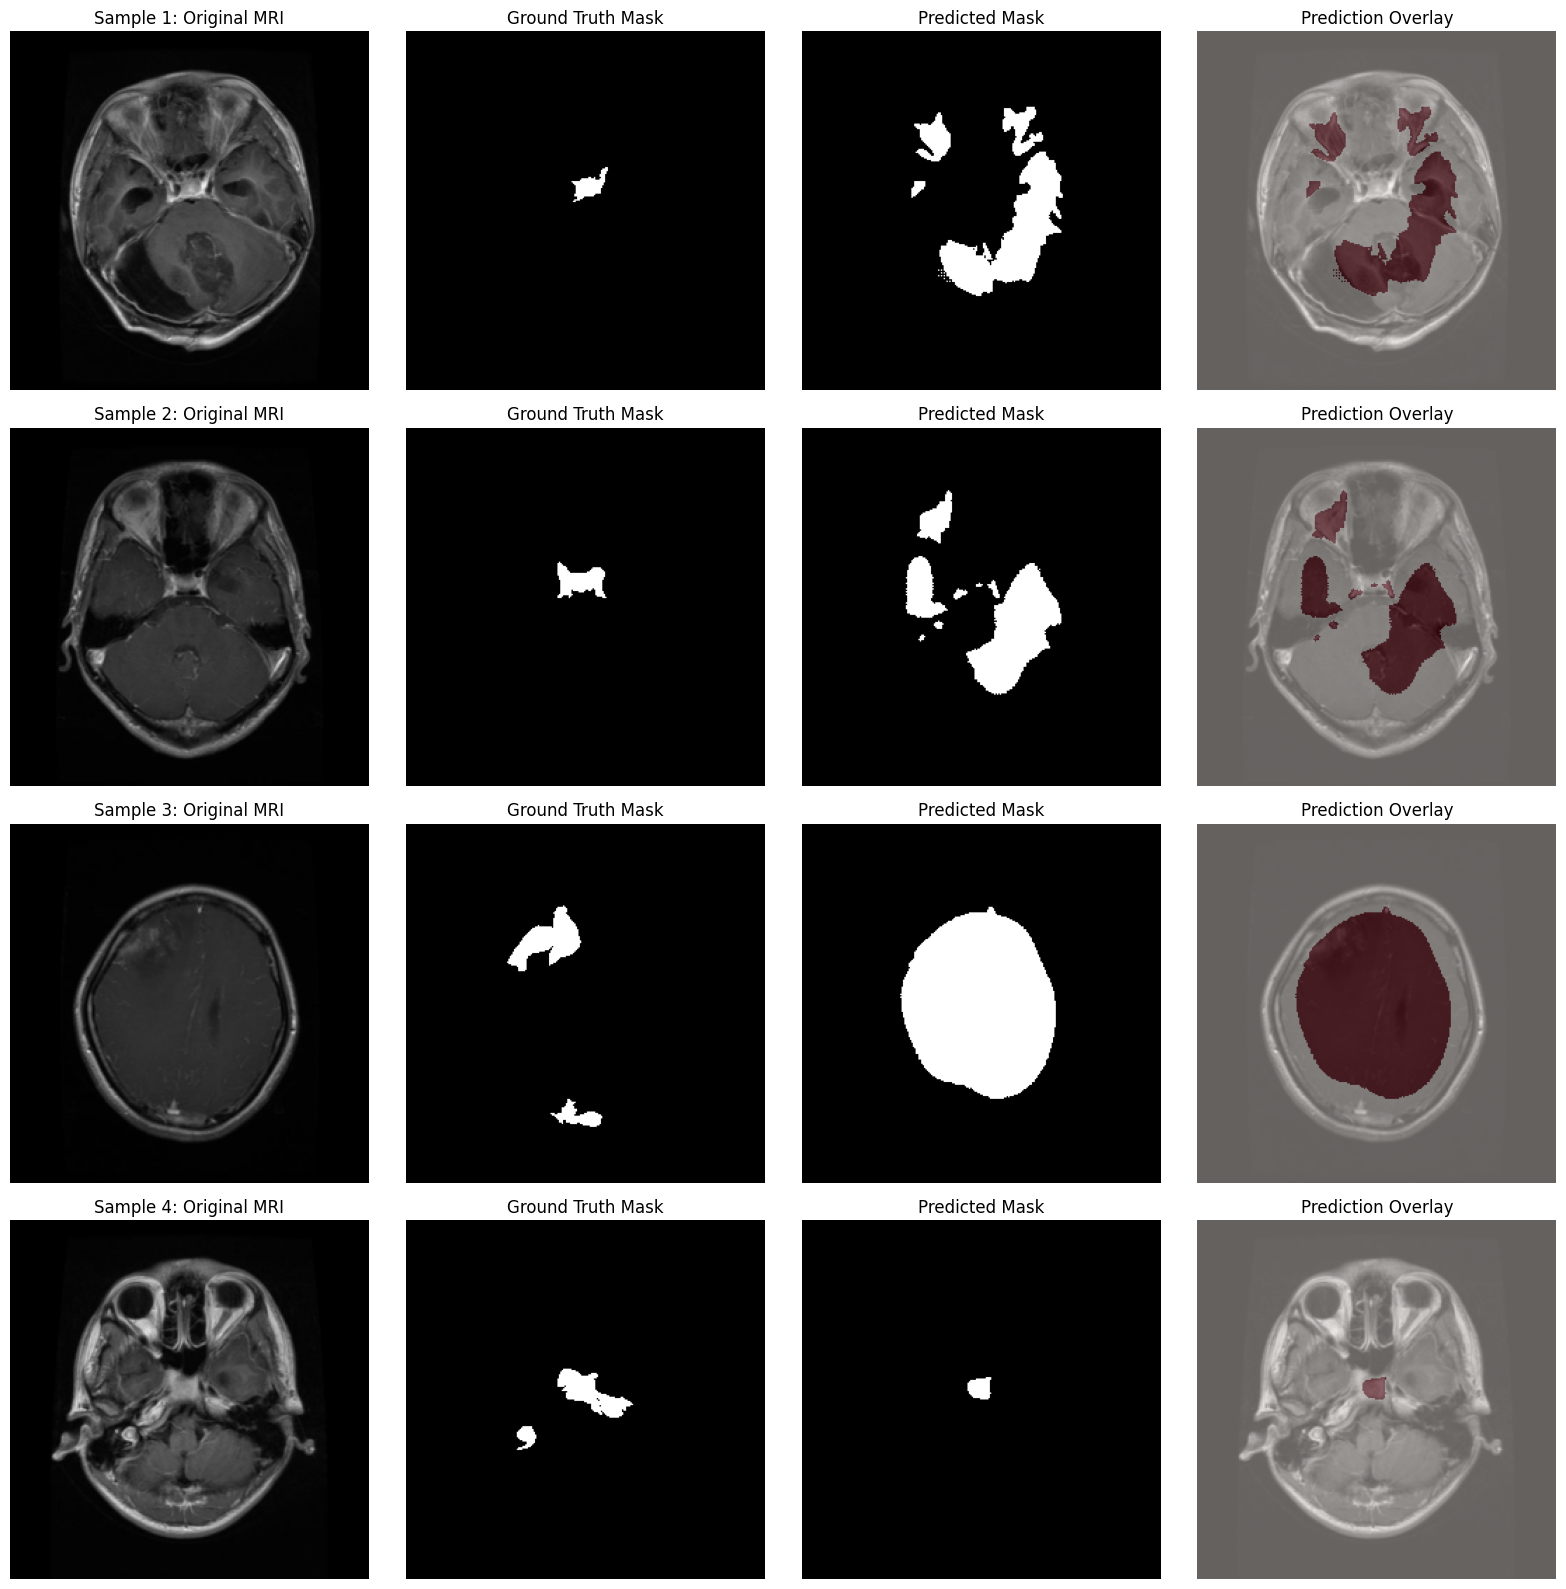

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

model.eval()

fig, axes = plt.subplots(4, 4, figsize=(16, 16))

with torch.no_grad():

    for i in range(4):

        image, mask = test_dataset[i]

        input_tensor = image.unsqueeze(0).to(device)

        output = model(input_tensor)

        probability = torch.sigmoid(output)[0, 0].cpu().numpy()

        prediction = (probability >= 0.9).astype(np.uint8)

        original = image.permute(1, 2, 0).numpy()
        ground_truth = mask.squeeze().numpy()

        axes[i, 0].imshow(original)
        axes[i, 0].set_title(f"Sample {i+1}: Original MRI")

        axes[i, 1].imshow(ground_truth, cmap="gray")
        axes[i, 1].set_title("Ground Truth Mask")

        axes[i, 2].imshow(prediction, cmap="gray")
        axes[i, 2].set_title("Predicted Mask")

        axes[i, 3].imshow(original)
        axes[i, 3].imshow(
            prediction,
            cmap="Reds",
            alpha=0.4
        )
        axes[i, 3].set_title("Prediction Overlay")

        for j in range(4):
            axes[i, j].axis("off")

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "model_outputs/BRISC_restored_model_visualization.png",
    dpi=150
)

plt.show()

Step 27.14 — Individual Sample Metrics

In [ ]:
import torch
import pandas as pd
import numpy as np
import os

model.eval()

threshold = 0.9
results = []

with torch.no_grad():

    for i in range(4):

        image, mask = test_dataset[i]

        input_tensor = image.unsqueeze(0).to(device)

        output = model(input_tensor)

        probability = torch.sigmoid(output)[0, 0].cpu()

        prediction = (
            probability >= threshold
        ).float()

        ground_truth = mask.squeeze().cpu().float()

        intersection = (
            prediction * ground_truth
        ).sum().item()

        predicted_pixels = prediction.sum().item()
        actual_pixels = ground_truth.sum().item()

        dice = (
            2 * intersection
        ) / (
            predicted_pixels + actual_pixels + 1e-7
        )

        iou = intersection / (
            predicted_pixels + actual_pixels
            - intersection + 1e-7
        )

        precision = intersection / (
            predicted_pixels + 1e-7
        )

        recall = intersection / (
            actual_pixels + 1e-7
        )

        results.append({
            "Sample": i + 1,
            "Ground Truth Pixels": int(actual_pixels),
            "Predicted Pixels": int(predicted_pixels),
            "Dice": round(dice, 4),
            "IoU": round(iou, 4),
            "Precision": round(precision, 4),
            "Recall": round(recall, 4)
        })


results_df = pd.DataFrame(results)

print("INDIVIDUAL TEST SAMPLE PERFORMANCE")
print("-" * 65)

print(results_df.to_string(index=False))

# Save results
output_dir = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "model_outputs"
)

os.makedirs(output_dir, exist_ok=True)

save_path = os.path.join(
    output_dir,
    "BRISC_individual_sample_metrics.csv"
)

results_df.to_csv(save_path, index=False)

print("\nResults saved successfully:")
print(save_path)

INDIVIDUAL TEST SAMPLE PERFORMANCE
-----------------------------------------------------------------
 Sample  Ground Truth Pixels  Predicted Pixels   Dice    IoU  Precision  Recall
      1                  286              4701 0.0000 0.0000     0.0000  0.0000
      2                  548              4633 0.0382 0.0195     0.0214  0.1807
      3                 1443             11332 0.1418 0.0763     0.0800  0.6279
      4                  996               216 0.3548 0.2156     0.9954  0.2159

Results saved successfully:
/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/BRISC_individual_sample_metrics.csv


Step 27.15 — Dataset Pair Verification

In [ ]:
print("TEST DATASET STRUCTURE")
print("-" * 50)

print("Dataset Type:", type(test_dataset))
print("Dataset Length:", len(test_dataset))

print("\nDataset Attributes:")

for key, value in vars(test_dataset).items():

    if isinstance(value, (list, tuple)):
        print(key, ":", len(value), "items")

    else:
        print(key, ":", type(value).__name__)

print("\nChecking First 5 Image-Mask Pairs")
print("-" * 50)

for i in range(min(5, len(test_dataset))):

    image, mask = test_dataset[i]

    print(
        f"Sample {i+1}: "
        f"Image Shape = {tuple(image.shape)}, "
        f"Mask Shape = {tuple(mask.shape)}, "
        f"Mask Pixels = {(mask > 0).sum().item()}"
    )

print("\nPair Structure Check Completed")

TEST DATASET STRUCTURE
--------------------------------------------------
Dataset Type: <class '__main__.BRISCTestDataset'>
Dataset Length: 860

Dataset Attributes:
image_dir : str
mask_dir : str
image_files : 860 items
transform : ToTensor

Checking First 5 Image-Mask Pairs
--------------------------------------------------
Sample 1: Image Shape = (3, 256, 256), Mask Shape = (1, 256, 256), Mask Pixels = 286
Sample 2: Image Shape = (3, 256, 256), Mask Shape = (1, 256, 256), Mask Pixels = 548
Sample 3: Image Shape = (3, 256, 256), Mask Shape = (1, 256, 256), Mask Pixels = 1443
Sample 4: Image Shape = (3, 256, 256), Mask Shape = (1, 256, 256), Mask Pixels = 996
Sample 5: Image Shape = (3, 256, 256), Mask Shape = (1, 256, 256), Mask Pixels = 295

Pair Structure Check Completed


Step 27.16 — Image-Mask Filename Matching

In [ ]:
import os

image_dir = test_dataset.image_dir
mask_dir = test_dataset.mask_dir

image_files = test_dataset.image_files

print("IMAGE-MASK FILENAME VERIFICATION")
print("-" * 60)

matched = 0
missing = []

for filename in image_files:

    stem = os.path.splitext(filename)[0]

    mask_path = os.path.join(mask_dir, stem + ".png")

    if os.path.exists(mask_path):
        matched += 1
    else:
        missing.append(filename)

print("Total Test Images:", len(image_files))
print("Matched Masks:", matched)
print("Missing Masks:", len(missing))

if missing:
    print("\nFirst Missing Filenames:")
    for filename in missing[:10]:
        print(filename)

else:
    print("\nAll Image-Mask filenames matched.")

IMAGE-MASK FILENAME VERIFICATION
------------------------------------------------------------
Total Test Images: 860
Matched Masks: 860
Missing Masks: 0

All Image-Mask filenames matched.


Step 27.17 — Mask and Prediction Pixel Distribution Analysis

In [ ]:
import torch
import numpy as np

model.eval()

total_gt_pixels = 0
total_pred_pixels = 0
total_pixels = 0

threshold = 0.9

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.sigmoid(outputs)

        predictions = (
            probabilities >= threshold
        ).float()

        total_gt_pixels += masks.sum().item()
        total_pred_pixels += predictions.sum().item()

        total_pixels += masks.numel()

gt_ratio = total_gt_pixels / total_pixels
pred_ratio = total_pred_pixels / total_pixels

print("TEST DATASET PIXEL DISTRIBUTION")
print("-" * 50)

print("Total Pixels:", int(total_pixels))
print("Ground Truth Pixels:", int(total_gt_pixels))
print("Predicted Pixels:", int(total_pred_pixels))

print("Ground Truth Foreground Ratio:", round(gt_ratio, 6))
print("Predicted Foreground Ratio:", round(pred_ratio, 6))

print("Prediction to Ground Truth Ratio:",
      round(pred_ratio / (gt_ratio + 1e-8), 2))

TEST DATASET PIXEL DISTRIBUTION
--------------------------------------------------
Total Pixels: 56360960
Ground Truth Pixels: 1036704
Predicted Pixels: 3665321
Ground Truth Foreground Ratio: 0.018394
Predicted Foreground Ratio: 0.065033
Prediction to Ground Truth Ratio: 3.54


Step 27.18 — Probability Distribution Analysis

In [ ]:
import torch
import numpy as np

model.eval()

all_probabilities = []

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.sigmoid(outputs)

        all_probabilities.append(
            probabilities.cpu().numpy().flatten()
        )

all_probabilities = np.concatenate(all_probabilities)

print("TEST PROBABILITY DISTRIBUTION")
print("-" * 50)

print("Minimum:", round(float(all_probabilities.min()), 6))
print("Maximum:", round(float(all_probabilities.max()), 6))
print("Mean:", round(float(all_probabilities.mean()), 6))
print("Median:", round(float(np.median(all_probabilities)), 6))
print("Standard Deviation:", round(float(all_probabilities.std()), 6))

for threshold_value in [0.5, 0.7, 0.8, 0.9, 0.95]:

    ratio = np.mean(
        all_probabilities >= threshold_value
    )

    print(
        f"Pixels above {threshold_value}: "
        f"{ratio:.4%}"
    )

TEST PROBABILITY DISTRIBUTION
--------------------------------------------------
Minimum: 0.006383
Maximum: 1.0
Mean: 0.241863
Median: 0.08412
Standard Deviation: 0.292703
Pixels above 0.5: 19.1026%
Pixels above 0.7: 13.8957%
Pixels above 0.8: 10.6292%
Pixels above 0.9: 6.5033%
Pixels above 0.95: 3.8082%


Step 27.19 — Training History Verification

In [ ]:
print("TRAINING HISTORY VERIFICATION")
print("-" * 50)

history_names = [
    "train_losses",
    "val_losses",
    "train_dices",
    "val_dices",
    "train_loss_history",
    "val_loss_history",
    "train_dice_history",
    "val_dice_history"
]

for name in history_names:

    if name in globals():

        values = globals()[name]

        print(f"\n{name}:")
        print("Values:", values)
        print("Length:", len(values))

print("\nCheckpoint Information")
print("-" * 50)

checkpoint_path = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "model_outputs/unet_brisc_weighted_best.pth"
)

print("Checkpoint Exists:", os.path.exists(checkpoint_path))
print("Checkpoint Size (MB):",
      round(os.path.getsize(checkpoint_path) / (1024 * 1024), 2)
      if os.path.exists(checkpoint_path) else "Not Found")

TRAINING HISTORY VERIFICATION
--------------------------------------------------

Checkpoint Information
--------------------------------------------------
Checkpoint Exists: True
Checkpoint Size (MB): 7.47


Step 27.20 — Validation Performance Verification

In [ ]:
import torch
import numpy as np

model.eval()

thresholds = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]

results = []

with torch.no_grad():

    for threshold_value in thresholds:

        total_intersection = 0
        total_predicted = 0
        total_actual = 0

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            probabilities = torch.sigmoid(outputs)

            predictions = (
                probabilities >= threshold_value
            ).float()

            total_intersection += (
                predictions * masks
            ).sum().item()

            total_predicted += predictions.sum().item()
            total_actual += masks.sum().item()

        dice = (
            2 * total_intersection
        ) / (
            total_predicted + total_actual + 1e-7
        )

        iou = total_intersection / (
            total_predicted + total_actual
            - total_intersection + 1e-7
        )

        precision = total_intersection / (
            total_predicted + 1e-7
        )

        recall = total_intersection / (
            total_actual + 1e-7
        )

        results.append({
            "Threshold": threshold_value,
            "Dice": round(dice, 4),
            "IoU": round(iou, 4),
            "Precision": round(precision, 4),
            "Recall": round(recall, 4)
        })

print("VALIDATION THRESHOLD COMPARISON")
print("-" * 70)

for result in results:
    print(result)

VALIDATION THRESHOLD COMPARISON
----------------------------------------------------------------------
{'Threshold': 0.5, 'Dice': 0.1618, 'IoU': 0.088, 'Precision': 0.0884, 'Recall': 0.9608}
{'Threshold': 0.6, 'Dice': 0.1819, 'IoU': 0.1001, 'Precision': 0.1006, 'Recall': 0.9476}
{'Threshold': 0.7, 'Dice': 0.21, 'IoU': 0.1173, 'Precision': 0.1184, 'Recall': 0.9291}
{'Threshold': 0.8, 'Dice': 0.2577, 'IoU': 0.1479, 'Precision': 0.1505, 'Recall': 0.8967}
{'Threshold': 0.9, 'Dice': 0.361, 'IoU': 0.2203, 'Precision': 0.2313, 'Recall': 0.8213}
{'Threshold': 0.95, 'Dice': 0.4794, 'IoU': 0.3152, 'Precision': 0.3585, 'Recall': 0.7232}


Step 27.21 — Final Test Evaluation at Threshold 0.95

In [ ]:
import torch
import pandas as pd
import os

model.eval()

threshold = 0.95

total_intersection = 0
total_predicted = 0
total_actual = 0
total_samples = 0

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        probabilities = torch.sigmoid(outputs)

        predictions = (
            probabilities >= threshold
        ).float()

        total_intersection += (
            predictions * masks
        ).sum().item()

        total_predicted += predictions.sum().item()
        total_actual += masks.sum().item()

        total_samples += images.size(0)

dice = (
    2 * total_intersection
) / (
    total_predicted + total_actual + 1e-7
)

iou = total_intersection / (
    total_predicted + total_actual
    - total_intersection + 1e-7
)

precision = total_intersection / (
    total_predicted + 1e-7
)

recall = total_intersection / (
    total_actual + 1e-7
)

print("FINAL TEST RESULTS - THRESHOLD 0.95")
print("-" * 55)

print("Threshold:", threshold)
print("Test Samples:", total_samples)
print("Dice:", round(dice, 4))
print("IoU:", round(iou, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

results = pd.DataFrame([{
    "Dataset": "BRISC Test",
    "Model": "Weighted U-Net",
    "Threshold": threshold,
    "Samples": total_samples,
    "Dice": round(dice, 4),
    "IoU": round(iou, 4),
    "Precision": round(precision, 4),
    "Recall": round(recall, 4)
}])

save_path = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "model_outputs/BRISC_final_segmentation_results_095.csv"
)

results.to_csv(save_path, index=False)

print("\nResults saved:", save_path)

FINAL TEST RESULTS - THRESHOLD 0.95
-------------------------------------------------------
Threshold: 0.95
Test Samples: 860
Dice: 0.494
IoU: 0.3281
Precision: 0.3663
Recall: 0.7584

Results saved: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/BRISC_final_segmentation_results_095.csv


Step 27.22 — Saving the Final Results Summary

In [ ]:
import pandas as pd
import os

output_dir = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "model_outputs"
)

comparison = pd.DataFrame([
    {
        "Model": "Weighted U-Net",
        "Threshold": 0.90,
        "Test Samples": 860,
        "Dice": 0.3732,
        "IoU": 0.2294,
        "Precision": 0.2393,
        "Recall": 0.8462
    },
    {
        "Model": "Weighted U-Net",
        "Threshold": 0.95,
        "Test Samples": 860,
        "Dice": 0.4940,
        "IoU": 0.3281,
        "Precision": 0.3663,
        "Recall": 0.7584
    }
])

save_path = os.path.join(
    output_dir,
    "BRISC_threshold_comparison.csv"
)

comparison.to_csv(save_path, index=False)

print("THRESHOLD COMPARISON SAVED")
print("-" * 50)
print(comparison.to_string(index=False))
print("\nFile:", save_path)

THRESHOLD COMPARISON SAVED
--------------------------------------------------
         Model  Threshold  Test Samples   Dice    IoU  Precision  Recall
Weighted U-Net       0.90           860 0.3732 0.2294     0.2393  0.8462
Weighted U-Net       0.95           860 0.4940 0.3281     0.3663  0.7584

File: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/BRISC_threshold_comparison.csv


Step 27.23 — MOTUM Dataset Structure Verification

In [ ]:
import os

base_path = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"
)

motum_paths = {
    "Normalized MRI": os.path.join(
        base_path, "MOTUM_normalized"
    ),
    "Binary Masks": os.path.join(
        base_path, "MOTUM_binary_masks"
    ),
    "2D Slices": os.path.join(
        base_path, "MOTUM_2D_slices"
    )
}

print("MOTUM DATASET VERIFICATION")
print("-" * 55)

for name, path in motum_paths.items():

    print("\n", name)
    print("Path:", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        items = os.listdir(path)
        print("Total Items:", len(items))
        print("First 5 Items:", items[:5])

print("\nMOTUM Structure Verification Completed")

MOTUM DATASET VERIFICATION
-------------------------------------------------------

 Normalized MRI
Path: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/MOTUM_normalized
Exists: True
Total Items: 65
First 5 Items: ['sub-0001', 'sub-0002', 'sub-0003', 'sub-0004', 'sub-0005']

 Binary Masks
Path: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/MOTUM_binary_masks
Exists: True
Total Items: 64
First 5 Items: ['sub-0001', 'sub-0002', 'sub-0003', 'sub-0004', 'sub-0005']

 2D Slices
Path: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/MOTUM_2D_slices
Exists: True
Total Items: 3
First 5 Items: ['train', 'validation', 'test']

MOTUM Structure Verification Completed


Step 27.24 — MOTUM 2D Slice Data Verification

In [ ]:
import os
import numpy as np

base_path = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "MOTUM_2D_slices"
)

splits = ["train", "validation", "test"]

print("MOTUM 2D SLICE VERIFICATION")
print("-" * 60)

for split in splits:

    split_path = os.path.join(base_path, split)

    files = [
        f for f in os.listdir(split_path)
        if f.endswith(".npz")
    ]

    print(f"\n{split.upper()} SPLIT")
    print("Total NPZ Files:", len(files))

    if len(files) == 0:
        print("No NPZ files found.")
        continue

    sample_path = os.path.join(
        split_path, files[0]
    )

    data = np.load(sample_path)

    print("Sample File:", files[0])
    print("Available Keys:", data.files)

    for key in data.files:

        value = data[key]

        if value.ndim > 0:
            print(
                key,
                "Shape:", value.shape,
                "Dtype:", value.dtype
            )
        else:
            print(key, "Value:", value)

    print("Sample Verification Completed")

    data.close()

print("\nMOTUM 2D Verification Finished")

MOTUM 2D SLICE VERIFICATION
------------------------------------------------------------

TRAIN SPLIT
Total NPZ Files: 929
Sample File: sub-0056_slice_000.npz
Available Keys: ['images', 'flair_mask', 't1ce_mask', 'subject_id', 'slice_index', 'modalities']
images Shape: (512, 512, 4) Dtype: float32
flair_mask Shape: (512, 512) Dtype: uint8
t1ce_mask Shape: (512, 512) Dtype: uint8
subject_id Value: sub-0056
slice_index Value: 0
modalities Shape: (4,) Dtype: <U5
Sample Verification Completed

VALIDATION SPLIT
Total NPZ Files: 225
Sample File: sub-0052_slice_000.npz
Available Keys: ['images', 'flair_mask', 't1ce_mask', 'subject_id', 'slice_index', 'modalities']
images Shape: (192, 256, 4) Dtype: float32
flair_mask Shape: (192, 256) Dtype: uint8
t1ce_mask Shape: (192, 256) Dtype: uint8
subject_id Value: sub-0052
slice_index Value: 0
modalities Shape: (4,) Dtype: <U5
Sample Verification Completed

TEST SPLIT
Total NPZ Files: 216
Sample File: sub-0023_slice_000.npz
Available Keys: ['images', 

Step 27.25 — MOTUM Dataset Sample Distribution

In [ ]:
import os
import numpy as np
from collections import Counter

base_path = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "MOTUM_2D_slices"
)

splits = ["train", "validation", "test"]

total_slices = 0
flair_empty = 0
t1ce_empty = 0

flair_foreground = 0
t1ce_foreground = 0

print("MOTUM MASK DISTRIBUTION ANALYSIS")
print("-" * 60)

for split in splits:

    split_path = os.path.join(base_path, split)

    files = sorted([
        f for f in os.listdir(split_path)
        if f.endswith(".npz")
    ])

    split_flair_empty = 0
    split_t1ce_empty = 0

    split_flair_pixels = 0
    split_t1ce_pixels = 0

    for filename in files:

        file_path = os.path.join(split_path, filename)

        with np.load(file_path) as data:

            flair_mask = data["flair_mask"]
            t1ce_mask = data["t1ce_mask"]

            split_flair_pixels += np.count_nonzero(flair_mask)
            split_t1ce_pixels += np.count_nonzero(t1ce_mask)

            if np.count_nonzero(flair_mask) == 0:
                split_flair_empty += 1

            if np.count_nonzero(t1ce_mask) == 0:
                split_t1ce_empty += 1

    total_slices += len(files)

    flair_empty += split_flair_empty
    t1ce_empty += split_t1ce_empty

    flair_foreground += split_flair_pixels
    t1ce_foreground += split_t1ce_pixels

    print(f"\n{split.upper()}")
    print("Total Slices:", len(files))
    print("FLAIR Empty Masks:", split_flair_empty)
    print("T1CE Empty Masks:", split_t1ce_empty)
    print("FLAIR Foreground Pixels:", split_flair_pixels)
    print("T1CE Foreground Pixels:", split_t1ce_pixels)

print("\nOVERALL SUMMARY")
print("-" * 60)
print("Total Slices:", total_slices)
print("Total FLAIR Empty Masks:", flair_empty)
print("Total T1CE Empty Masks:", t1ce_empty)
print("Total FLAIR Foreground Pixels:", flair_foreground)
print("Total T1CE Foreground Pixels:", t1ce_foreground)

MOTUM MASK DISTRIBUTION ANALYSIS
------------------------------------------------------------

TRAIN
Total Slices: 929
FLAIR Empty Masks: 520
T1CE Empty Masks: 646
FLAIR Foreground Pixels: 1716296
T1CE Foreground Pixels: 575099

VALIDATION
Total Slices: 225
FLAIR Empty Masks: 135
T1CE Empty Masks: 160
FLAIR Foreground Pixels: 344212
T1CE Foreground Pixels: 139810

TEST
Total Slices: 216
FLAIR Empty Masks: 92
T1CE Empty Masks: 140
FLAIR Foreground Pixels: 572961
T1CE Foreground Pixels: 143028

OVERALL SUMMARY
------------------------------------------------------------
Total Slices: 1370
Total FLAIR Empty Masks: 747
Total T1CE Empty Masks: 946
Total FLAIR Foreground Pixels: 2633469
Total T1CE Foreground Pixels: 857937


Step 27.26 — Subject Split and Mask Integrity Verification

In [ ]:
import os
import numpy as np

base_path = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "MOTUM_2D_slices"
)

splits = ["train", "validation", "test"]

subject_sets = {
    split: set() for split in splits
}

invalid_masks = 0
invalid_images = 0
shape_mismatches = 0
total_files = 0

for split in splits:

    split_path = os.path.join(base_path, split)

    files = [
        f for f in os.listdir(split_path)
        if f.endswith(".npz")
    ]

    for filename in files:

        path = os.path.join(split_path, filename)

        with np.load(path) as data:

            images = data["images"]
            flair_mask = data["flair_mask"]
            t1ce_mask = data["t1ce_mask"]

            subject_id = str(data["subject_id"].item())
            subject_sets[split].add(subject_id)

            total_files += 1

            if not np.isfinite(images).all():
                invalid_images += 1

            if (
                images.shape[:2] != flair_mask.shape
                or images.shape[:2] != t1ce_mask.shape
            ):
                shape_mismatches += 1

            if not set(np.unique(flair_mask)).issubset({0, 1}):
                invalid_masks += 1

            if not set(np.unique(t1ce_mask)).issubset({0, 1}):
                invalid_masks += 1

print("MOTUM INTEGRITY VERIFICATION")
print("-" * 55)

for split in splits:
    print(split.upper(), "Unique Subjects:", len(subject_sets[split]))

train_val = subject_sets["train"] & subject_sets["validation"]
train_test = subject_sets["train"] & subject_sets["test"]
val_test = subject_sets["validation"] & subject_sets["test"]

print("\nSUBJECT OVERLAP")
print("Train-Validation:", len(train_val))
print("Train-Test:", len(train_test))
print("Validation-Test:", len(val_test))

print("\nDATA INTEGRITY")
print("Total NPZ Files:", total_files)
print("Invalid Images:", invalid_images)
print("Invalid Masks:", invalid_masks)
print("Shape Mismatches:", shape_mismatches)

MOTUM INTEGRITY VERIFICATION
-------------------------------------------------------
TRAIN Unique Subjects: 44
VALIDATION Unique Subjects: 10
TEST Unique Subjects: 10

SUBJECT OVERLAP
Train-Validation: 0
Train-Test: 0
Validation-Test: 0

DATA INTEGRITY
Total NPZ Files: 1370
Invalid Images: 0
Invalid Masks: 0
Shape Mismatches: 0


Step 27.27 — Creating the MOTUM FLAIR Segmentation DataLoader

In [ ]:

import os
import glob
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

BASE_PATH = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/MOTUM_2D_slices"

class MOTUMFlairDataset(Dataset):
    def __init__(self, split):
        self.folder = os.path.join(BASE_PATH, split)
        self.files = sorted(glob.glob(os.path.join(self.folder, "*.npz")))

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        data = np.load(self.files[index])

        image = data["images"].astype(np.float32)
        mask = data["flair_mask"].astype(np.float32)

        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).unsqueeze(0)

        image = F.interpolate(
            image.unsqueeze(0),
            size=(256, 256),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)

        mask = F.interpolate(
            mask.unsqueeze(0),
            size=(256, 256),
            mode="nearest"
        ).squeeze(0)

        return image, mask


train_dataset = MOTUMFlairDataset("train")
val_dataset = MOTUMFlairDataset("validation")
test_dataset = MOTUMFlairDataset("test")

train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=4, shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=4, shuffle=False, num_workers=0
)

print("MOTUM FLAIR DATALOADER")
print("----------------------------------------")
print("Train Samples:", len(train_dataset))
print("Validation Samples:", len(val_dataset))
print("Test Samples:", len(test_dataset))

images, masks = next(iter(train_loader))

print("\nBATCH VERIFICATION")
print("----------------------------------------")
print("Image Shape:", images.shape)
print("Mask Shape:", masks.shape)
print("Image Channels:", images.shape[1])
print("Mask Unique Values:", torch.unique(masks))
print("Images Finite:", torch.isfinite(images).all().item())
print("Masks Finite:", torch.isfinite(masks).all().item())
print("Input Size:", images.shape[-2:])


MOTUM FLAIR DATALOADER
----------------------------------------
Train Samples: 929
Validation Samples: 225
Test Samples: 216

BATCH VERIFICATION
----------------------------------------
Image Shape: torch.Size([4, 4, 256, 256])
Mask Shape: torch.Size([4, 1, 256, 256])
Image Channels: 4
Mask Unique Values: tensor([0.])
Images Finite: True
Masks Finite: True
Input Size: torch.Size([256, 256])


step 27.28— FLAIR Mask Distribution Verification

In [ ]:

def verify_flair_masks(dataset, split_name):
    empty_count = 0
    non_empty_count = 0
    total_foreground = 0

    for i in range(len(dataset)):
        _, mask = dataset[i]
        foreground = int((mask > 0).sum().item())

        if foreground == 0:
            empty_count += 1
        else:
            non_empty_count += 1

        total_foreground += foreground

    print(f"\n{split_name} FLAIR MASK ANALYSIS")
    print("----------------------------------------")
    print("Total Slices:", len(dataset))
    print("Empty Masks:", empty_count)
    print("Non-Empty Masks:", non_empty_count)
    print("Total Foreground Pixels:", total_foreground)


verify_flair_masks(train_dataset, "TRAIN")
verify_flair_masks(val_dataset, "VALIDATION")
verify_flair_masks(test_dataset, "TEST")

# Find one non-empty training sample
for i in range(len(train_dataset)):
    image, mask = train_dataset[i]

    if (mask > 0).any():
        print("\nNON-EMPTY SAMPLE FOUND")
        print("Sample Index:", i)
        print("Image Shape:", image.shape)
        print("Mask Shape:", mask.shape)
        print("Foreground Pixels:", int((mask > 0).sum().item()))
        print("Mask Values:", torch.unique(mask))
        break



TRAIN FLAIR MASK ANALYSIS
----------------------------------------
Total Slices: 929
Empty Masks: 520
Non-Empty Masks: 409
Total Foreground Pixels: 1064058

VALIDATION FLAIR MASK ANALYSIS
----------------------------------------
Total Slices: 225
Empty Masks: 135
Non-Empty Masks: 90
Total Foreground Pixels: 230660

TEST FLAIR MASK ANALYSIS
----------------------------------------
Total Slices: 216
Empty Masks: 92
Non-Empty Masks: 124
Total Foreground Pixels: 378565

NON-EMPTY SAMPLE FOUND
Sample Index: 10
Image Shape: torch.Size([4, 256, 256])
Mask Shape: torch.Size([1, 256, 256])
Foreground Pixels: 1022
Mask Values: tensor([0., 1.])


Step 27.29 — Creating the MOTUM FLAIR U-Net Model

In [ ]:

import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class MOTUMUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder1 = DoubleConv(4, 16)
        self.pool1 = nn.MaxPool2d(2)

        self.encoder2 = DoubleConv(16, 32)
        self.pool2 = nn.MaxPool2d(2)

        self.encoder3 = DoubleConv(32, 64)
        self.pool3 = nn.MaxPool2d(2)

        self.encoder4 = DoubleConv(64, 128)
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(128, 256)

        self.up4 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.decoder4 = DoubleConv(256, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.decoder3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.decoder2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.decoder1 = DoubleConv(32, 16)

        self.output = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool1(e1))
        e3 = self.encoder3(self.pool2(e2))
        e4 = self.encoder4(self.pool3(e3))

        b = self.bottleneck(self.pool4(e4))

        d4 = self.up4(b)
        d4 = self.decoder4(torch.cat([e4, d4], dim=1))

        d3 = self.up3(d4)
        d3 = self.decoder3(torch.cat([e3, d3], dim=1))

        d2 = self.up2(d3)
        d2 = self.decoder2(torch.cat([e2, d2], dim=1))

        d1 = self.up1(d2)
        d1 = self.decoder1(torch.cat([e1, d1], dim=1))

        return self.output(d1)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

motum_flair_model = MOTUMUNet().to(device)

sample_images, sample_masks = next(iter(train_loader))
sample_images = sample_images.to(device)

with torch.no_grad():
    sample_output = motum_flair_model(sample_images)

print("MOTUM FLAIR U-NET MODEL")
print("----------------------------------------")
print("Device:", device)
print("Input Shape:", sample_images.shape)
print("Output Shape:", sample_output.shape)
print("Target Shape:", sample_masks.shape)
print("Total Parameters:", sum(p.numel() for p in motum_flair_model.parameters()))
print("Model Created Successfully")


MOTUM FLAIR U-NET MODEL
----------------------------------------
Device: cpu
Input Shape: torch.Size([4, 4, 256, 256])
Output Shape: torch.Size([4, 1, 256, 256])
Target Shape: torch.Size([4, 1, 256, 256])
Total Parameters: 1944193
Model Created Successfully


Step 27.30 — FLAIR U-Net Training Setup

In [ ]:

import os
import torch
import torch.nn as nn

# Training configuration
LEARNING_RATE = 0.0005
EPOCHS = 1

criterion_bce = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    motum_flair_model.parameters(),
    lr=LEARNING_RATE
)

def dice_loss_function(logits, targets, smooth=1e-6):
    probabilities = torch.sigmoid(logits)

    probabilities = probabilities.view(probabilities.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    intersection = (probabilities * targets).sum(dim=1)

    dice = (2 * intersection + smooth) / (
        probabilities.sum(dim=1) + targets.sum(dim=1) + smooth
    )

    return 1 - dice.mean()


def combined_loss(logits, targets):
    bce = criterion_bce(logits, targets)
    dice = dice_loss_function(logits, targets)

    return bce + dice


os.makedirs("model_outputs", exist_ok=True)

CHECKPOINT_PATH = "model_outputs/motum_flair_unet_best.pth"

print("MOTUM FLAIR TRAINING SETUP")
print("----------------------------------------")
print("Device:", device)
print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Loss: BCE + Dice Loss")
print("Optimizer: Adam")
print("Checkpoint:", CHECKPOINT_PATH)
print("Training Setup Ready")


MOTUM FLAIR TRAINING SETUP
----------------------------------------
Device: cpu
Epochs: 1
Learning Rate: 0.0005
Loss: BCE + Dice Loss
Optimizer: Adam
Checkpoint: model_outputs/motum_flair_unet_best.pth
Training Setup Ready


Step 27.31 — MOTUM FLAIR U-Net Training

In [ ]:

import time
import numpy as np

def calculate_dice(logits, targets, threshold=0.5, smooth=1e-6):
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities > threshold).float()

    predictions = predictions.view(predictions.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    intersection = (predictions * targets).sum(dim=1)

    dice = (2 * intersection + smooth) / (
        predictions.sum(dim=1) + targets.sum(dim=1) + smooth
    )

    return dice.mean().item()


best_val_dice = -1.0

for epoch in range(EPOCHS):
    start_time = time.time()

    motum_flair_model.train()

    train_losses = []
    train_dices = []

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = motum_flair_model(images)
        loss = combined_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())
        train_dices.append(calculate_dice(outputs.detach(), masks))

    motum_flair_model.eval()

    val_losses = []
    val_dices = []

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = motum_flair_model(images)
            loss = combined_loss(outputs, masks)

            val_losses.append(loss.item())
            val_dices.append(calculate_dice(outputs, masks))

    train_loss = np.mean(train_losses)
    val_loss = np.mean(val_losses)

    train_dice = np.mean(train_dices)
    val_dice = np.mean(val_dices)

    if val_dice > best_val_dice:
        best_val_dice = val_dice

        torch.save({
            "model_state_dict": motum_flair_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "epoch": epoch + 1,
            "val_dice": val_dice
        }, CHECKPOINT_PATH)

    elapsed = time.time() - start_time

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print("----------------------------------------")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Train Dice: {train_dice:.4f}")
    print(f"Validation Dice: {val_dice:.4f}")
    print(f"Best Validation Dice: {best_val_dice:.4f}")
    print(f"Time: {elapsed / 60:.2f} minutes")

print("\nMOTUM FLAIR TRAINING COMPLETED")
print("Checkpoint Saved:", os.path.exists(CHECKPOINT_PATH))



Epoch 1/1
----------------------------------------
Train Loss: 1.4340
Validation Loss: 1.2649
Train Dice: 0.3376
Validation Dice: 0.5719
Best Validation Dice: 0.5719
Time: 9.95 minutes

MOTUM FLAIR TRAINING COMPLETED
Checkpoint Saved: True


Step 27.32 — Best Model Restore and Test Evaluation

In [ ]:

import torch
import numpy as np
import os

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

motum_flair_model.load_state_dict(
    checkpoint["model_state_dict"]
)

motum_flair_model.eval()

test_dices = []
test_losses = []

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = motum_flair_model(images)

        loss = combined_loss(outputs, masks)
        dice = calculate_dice(outputs, masks, threshold=0.5)

        test_losses.append(loss.item())
        test_dices.append(dice)

print("MOTUM FLAIR FINAL TEST EVALUATION")
print("----------------------------------------")
print("Test Samples:", len(test_dataset))
print("Test Loss:", f"{np.mean(test_losses):.4f}")
print("Test Dice:", f"{np.mean(test_dices):.4f}")
print("Evaluation Threshold: 0.50")
print("Restored Checkpoint Epoch:", checkpoint["epoch"])
print("Checkpoint Validation Dice:", f"{checkpoint['val_dice']:.4f}")
print("Test Evaluation Completed")


MOTUM FLAIR FINAL TEST EVALUATION
----------------------------------------
Test Samples: 216
Test Loss: 1.2412
Test Dice: 0.6115
Evaluation Threshold: 0.50
Restored Checkpoint Epoch: 1
Checkpoint Validation Dice: 0.5719
Test Evaluation Completed


step 27.33 — MOTUM FLAIR Detailed Test Metrics

In [ ]:

import numpy as np
import torch

total_tp = 0
total_fp = 0
total_fn = 0
total_tn = 0

motum_flair_model.eval()

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = motum_flair_model(images)
        probabilities = torch.sigmoid(logits)

        predictions = (probabilities > 0.50).float()

        total_tp += ((predictions == 1) & (masks == 1)).sum().item()
        total_fp += ((predictions == 1) & (masks == 0)).sum().item()
        total_fn += ((predictions == 0) & (masks == 1)).sum().item()
        total_tn += ((predictions == 0) & (masks == 0)).sum().item()

dice = (2 * total_tp) / (
    2 * total_tp + total_fp + total_fn + 1e-8
)

iou = total_tp / (
    total_tp + total_fp + total_fn + 1e-8
)

precision = total_tp / (
    total_tp + total_fp + 1e-8
)

recall = total_tp / (
    total_tp + total_fn + 1e-8
)

print("MOTUM FLAIR DETAILED TEST METRICS")
print("----------------------------------------")
print("True Positive:", int(total_tp))
print("False Positive:", int(total_fp))
print("False Negative:", int(total_fn))
print("True Negative:", int(total_tn))
print("----------------------------------------")
print("Dice:", f"{dice:.4f}")
print("IoU:", f"{iou:.4f}")
print("Precision:", f"{precision:.4f}")
print("Recall:", f"{recall:.4f}")
print("Threshold: 0.50")


MOTUM FLAIR DETAILED TEST METRICS
----------------------------------------
True Positive: 320271
False Positive: 275212
False Negative: 58294
True Negative: 13501999
----------------------------------------
Dice: 0.6576
IoU: 0.4899
Precision: 0.5378
Recall: 0.8460
Threshold: 0.50


Step 27.34 — MOTUM FLAIR Prediction Sample Test

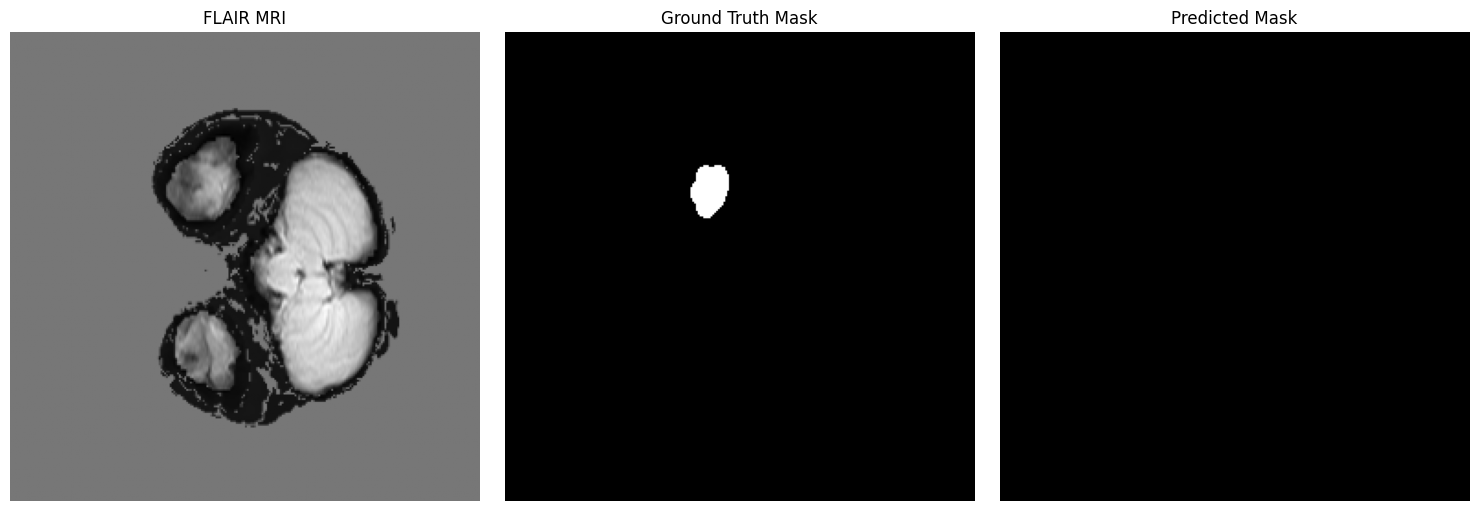

MOTUM FLAIR SAMPLE PREDICTION
----------------------------------------
Test Sample Index: 3
Ground Truth Pixels: 457
Predicted Pixels: 0
Threshold: 0.50


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import torch

motum_flair_model.eval()

selected_sample = None

for i in range(len(test_dataset)):
    image, mask = test_dataset[i]

    if mask.sum() > 0:
        selected_sample = (image, mask, i)
        break

image, true_mask, sample_index = selected_sample

with torch.no_grad():
    input_tensor = image.unsqueeze(0).to(device)
    logits = motum_flair_model(input_tensor)
    probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

predicted_mask = (probability > 0.50).astype(np.uint8)

# Display the FLAIR channel, ground truth, and prediction
flair_image = image[0].cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(flair_image, cmap="gray")
axes[0].set_title("FLAIR MRI")

axes[1].imshow(true_mask[0].cpu().numpy(), cmap="gray")
axes[1].set_title("Ground Truth Mask")

axes[2].imshow(predicted_mask, cmap="gray")
axes[2].set_title("Predicted Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("MOTUM FLAIR SAMPLE PREDICTION")
print("----------------------------------------")
print("Test Sample Index:", sample_index)
print("Ground Truth Pixels:", int(true_mask.sum().item()))
print("Predicted Pixels:", int(predicted_mask.sum()))
print("Threshold: 0.50")


Step 27.35 Checkpoint Recovery Search

In [ ]:

import os

# Mount Google Drive if needed
from google.colab import drive
drive.mount("/content/drive")

search_roots = [
    "/content/model_outputs",
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"
]

checkpoint_name = "motum_flair_unet_best.pth"
found_files = []

for root in search_roots:
    if os.path.exists(root):
        for current_root, dirs, files in os.walk(root):
            if checkpoint_name in files:
                found_files.append(
                    os.path.join(current_root, checkpoint_name)
                )

print("CHECKPOINT RECOVERY SEARCH")
print("----------------------------------------")

if found_files:
    for path in found_files:
        print("Found:", path)
else:
    print("Checkpoint not found in searched locations.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CHECKPOINT RECOVERY SEARCH
----------------------------------------
Checkpoint not found in searched locations.


Step 27.36 — Recreating the MOTUM FLAIR Model

In [ ]:

import os
import torch
import torch.nn as nn

# Google Drive output directory
OUTPUT_DIR = (
    "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/"
    "model_outputs"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

CHECKPOINT_PATH = os.path.join(
    OUTPUT_DIR,
    "motum_flair_unet_best.pth"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# U-Net building block
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# MOTUM FLAIR U-Net
class MOTUMUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder1 = DoubleConv(4, 16)
        self.pool1 = nn.MaxPool2d(2)

        self.encoder2 = DoubleConv(16, 32)
        self.pool2 = nn.MaxPool2d(2)

        self.encoder3 = DoubleConv(32, 64)
        self.pool3 = nn.MaxPool2d(2)

        self.encoder4 = DoubleConv(64, 128)
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(128, 256)

        self.up4 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.decoder4 = DoubleConv(256, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.decoder3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.decoder2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.decoder1 = DoubleConv(32, 16)

        self.output = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool1(e1))
        e3 = self.encoder3(self.pool2(e2))
        e4 = self.encoder4(self.pool3(e3))

        b = self.bottleneck(self.pool4(e4))

        d4 = self.decoder4(
            torch.cat([e4, self.up4(b)], dim=1)
        )
        d3 = self.decoder3(
            torch.cat([e3, self.up3(d4)], dim=1)
        )
        d2 = self.decoder2(
            torch.cat([e2, self.up2(d3)], dim=1)
        )
        d1 = self.decoder1(
            torch.cat([e1, self.up1(d2)], dim=1)
        )

        return self.output(d1)


# Create model
motum_flair_model = MOTUMUNet().to(device)

# Loss and optimizer
criterion_bce = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    motum_flair_model.parameters(),
    lr=0.0005
)

EPOCHS = 1

print("MOTUM FLAIR MODEL RESTORATION SETUP")
print("----------------------------------------")
print("Device:", device)
print("Model Parameters:",
      sum(p.numel() for p in motum_flair_model.parameters()))
print("Checkpoint Path:", CHECKPOINT_PATH)
print("Epochs:", EPOCHS)
print("Model Created Successfully")


MOTUM FLAIR MODEL RESTORATION SETUP
----------------------------------------
Device: cpu
Model Parameters: 1944193
Checkpoint Path: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/motum_flair_unet_best.pth
Epochs: 1
Model Created Successfully


Step 27.37 — Recreating the MOTUM FLAIR Dataset and DataLoader

In [ ]:

import os
import glob
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Dataset paths
BASE_PATH = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/MOTUM_2D_slices"
OUTPUT_DIR = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs"
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "motum_flair_unet_best.pth")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Dataset class
class MOTUMFlairDataset(Dataset):
    def __init__(self, split):
        self.files = sorted(
            glob.glob(os.path.join(BASE_PATH, split, "*.npz"))
        )

        if len(self.files) == 0:
            raise RuntimeError(f"No NPZ files found in {split}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        data = np.load(self.files[index])

        image = data["images"].astype(np.float32)
        mask = data["flair_mask"].astype(np.float32)

        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).unsqueeze(0)

        image = F.interpolate(
            image.unsqueeze(0),
            size=(256, 256),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)

        mask = F.interpolate(
            mask.unsqueeze(0),
            size=(256, 256),
            mode="nearest"
        ).squeeze(0)

        return image, mask


# Create datasets
train_dataset = MOTUMFlairDataset("train")
val_dataset = MOTUMFlairDataset("validation")
test_dataset = MOTUMFlairDataset("test")

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=4, shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=4, shuffle=False, num_workers=0
)

# Loss function
criterion_bce = nn.BCEWithLogitsLoss()

def combined_loss(predictions, targets):
    bce = criterion_bce(predictions, targets)

    probabilities = torch.sigmoid(predictions)
    intersection = (probabilities * targets).sum(dim=(1, 2, 3))
    denominator = (
        probabilities.sum(dim=(1, 2, 3)) +
        targets.sum(dim=(1, 2, 3))
    )

    dice = (2.0 * intersection + 1e-6) / (denominator + 1e-6)
    dice_loss = 1.0 - dice.mean()

    return bce + dice_loss


def calculate_dice(predictions, targets):
    probabilities = torch.sigmoid(predictions)
    predicted_masks = (probabilities > 0.5).float()

    intersection = (predicted_masks * targets).sum(dim=(1, 2, 3))
    denominator = (
        predicted_masks.sum(dim=(1, 2, 3)) +
        targets.sum(dim=(1, 2, 3))
    )

    dice = (2.0 * intersection + 1e-6) / (denominator + 1e-6)
    return dice.mean().item()


# Recreate optimizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
motum_flair_model = motum_flair_model.to(device)

optimizer = torch.optim.Adam(
    motum_flair_model.parameters(),
    lr=0.0005
)

# One epoch training
EPOCHS = 1
best_val_dice = -1.0

start_time = time.time()

for epoch in range(EPOCHS):
    motum_flair_model.train()

    train_loss_total = 0.0
    train_dice_total = 0.0

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = motum_flair_model(images)
        loss = combined_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        train_loss_total += loss.item()
        train_dice_total += calculate_dice(outputs.detach(), masks)

    train_loss = train_loss_total / len(train_loader)
    train_dice = train_dice_total / len(train_loader)

    # Validation
    motum_flair_model.eval()

    val_loss_total = 0.0
    val_dice_total = 0.0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = motum_flair_model(images)
            loss = combined_loss(outputs, masks)

            val_loss_total += loss.item()
            val_dice_total += calculate_dice(outputs, masks)

    val_loss = val_loss_total / len(val_loader)
    val_dice = val_dice_total / len(val_loader)

    print(f"Epoch: {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Dice: {train_dice:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Dice: {val_dice:.4f}")

    if val_dice > best_val_dice:
        best_val_dice = val_dice

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": motum_flair_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_dice": best_val_dice
        }, CHECKPOINT_PATH)

        print("Best model saved successfully.")

elapsed_time = (time.time() - start_time) / 60

print("\nMOTUM FLAIR TRAINING COMPLETED")
print("--------------------------------")
print("Training Samples:", len(train_dataset))
print("Validation Samples:", len(val_dataset))
print("Test Samples:", len(test_dataset))
print(f"Best Validation Dice: {best_val_dice:.4f}")
print(f"Training Time: {elapsed_time:.2f} minutes")
print("Checkpoint Exists:", os.path.exists(CHECKPOINT_PATH))
print("Checkpoint Path:", CHECKPOINT_PATH)


Epoch: 1/1
Train Loss: 1.1668
Train Dice: 0.5063
Validation Loss: 1.0432
Validation Dice: 0.7336
Best model saved successfully.

MOTUM FLAIR TRAINING COMPLETED
--------------------------------
Training Samples: 929
Validation Samples: 225
Test Samples: 216
Best Validation Dice: 0.7336
Training Time: 10.19 minutes
Checkpoint Exists: True
Checkpoint Path: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/motum_flair_unet_best.pth


Step 27.38 — Model Checkpoint Verification

In [ ]:
import os
import torch

CHECKPOINT_PATH = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/motum_flair_unet_best.pth"

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

motum_flair_model.load_state_dict(checkpoint["model_state_dict"])
motum_flair_model.eval()

print("MOTUM FLAIR CHECKPOINT VERIFICATION")
print("-----------------------------------")
print("Checkpoint Exists:", os.path.exists(CHECKPOINT_PATH))
print("Saved Epoch:", checkpoint["epoch"])
print("Saved Validation Dice:", checkpoint["val_dice"])
print("Model Loaded Successfully")

MOTUM FLAIR CHECKPOINT VERIFICATION
-----------------------------------
Checkpoint Exists: True
Saved Epoch: 1
Saved Validation Dice: 0.7336305043059634
Model Loaded Successfully


Step 27.39 — MOTUM FLAIR Final Test Evaluation

In [ ]:
import torch
import numpy as np

motum_flair_model.eval()

TP = 0
FP = 0
FN = 0
TN = 0

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = motum_flair_model(images)
        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities > 0.50).float()

        TP += ((predictions == 1) & (masks == 1)).sum().item()
        FP += ((predictions == 1) & (masks == 0)).sum().item()
        FN += ((predictions == 0) & (masks == 1)).sum().item()
        TN += ((predictions == 0) & (masks == 0)).sum().item()

dice = (2 * TP) / (2 * TP + FP + FN + 1e-8)
iou = TP / (TP + FP + FN + 1e-8)
precision = TP / (TP + FP + 1e-8)
recall = TP / (TP + FN + 1e-8)

print("MOTUM FLAIR FINAL TEST RESULTS")
print("--------------------------------")
print("Test Samples:", len(test_dataset))
print("Threshold: 0.50")
print("True Positive:", TP)
print("False Positive:", FP)
print("False Negative:", FN)
print("True Negative:", TN)
print("--------------------------------")
print(f"Test Dice: {dice:.4f}")
print(f"Test IoU: {iou:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")

MOTUM FLAIR FINAL TEST RESULTS
--------------------------------
Test Samples: 216
Threshold: 0.50
True Positive: 292786
False Positive: 126788
False Negative: 85779
True Negative: 13650423
--------------------------------
Test Dice: 0.7337
Test IoU: 0.5794
Test Precision: 0.6978
Test Recall: 0.7734


Step 27.40 — Saving Test Results to Google Drive

In [ ]:
import os
import pandas as pd

results = {
    "Dataset": ["MOTUM"],
    "Target": ["FLAIR"],
    "Model": ["2D U-Net"],
    "Test Samples": [216],
    "Threshold": [0.50],
    "Dice": [0.7337],
    "IoU": [0.5794],
    "Precision": [0.6978],
    "Recall": [0.7734],
    "TP": [292786],
    "FP": [126788],
    "FN": [85779],
    "TN": [13650423]
}

results_df = pd.DataFrame(results)

save_path = os.path.join(
    OUTPUT_DIR,
    "MOTUM_FLAIR_final_test_results.csv"
)

results_df.to_csv(save_path, index=False)

print("Results Saved Successfully")
print("File:", save_path)
print(results_df.to_string(index=False))

Results Saved Successfully
File: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/MOTUM_FLAIR_final_test_results.csv
Dataset Target    Model  Test Samples  Threshold   Dice    IoU  Precision  Recall     TP     FP    FN       TN
  MOTUM  FLAIR 2D U-Net           216        0.5 0.7337 0.5794     0.6978  0.7734 292786 126788 85779 13650423


Step 27.41 — MOTUM FLAIR Prediction Visualization

MOTUM FLAIR PREDICTION ANALYSIS
--------------------------------
Sample Index: 10
Ground Truth Pixels: 4965
Predicted Pixels: 2079
Threshold: 0.50


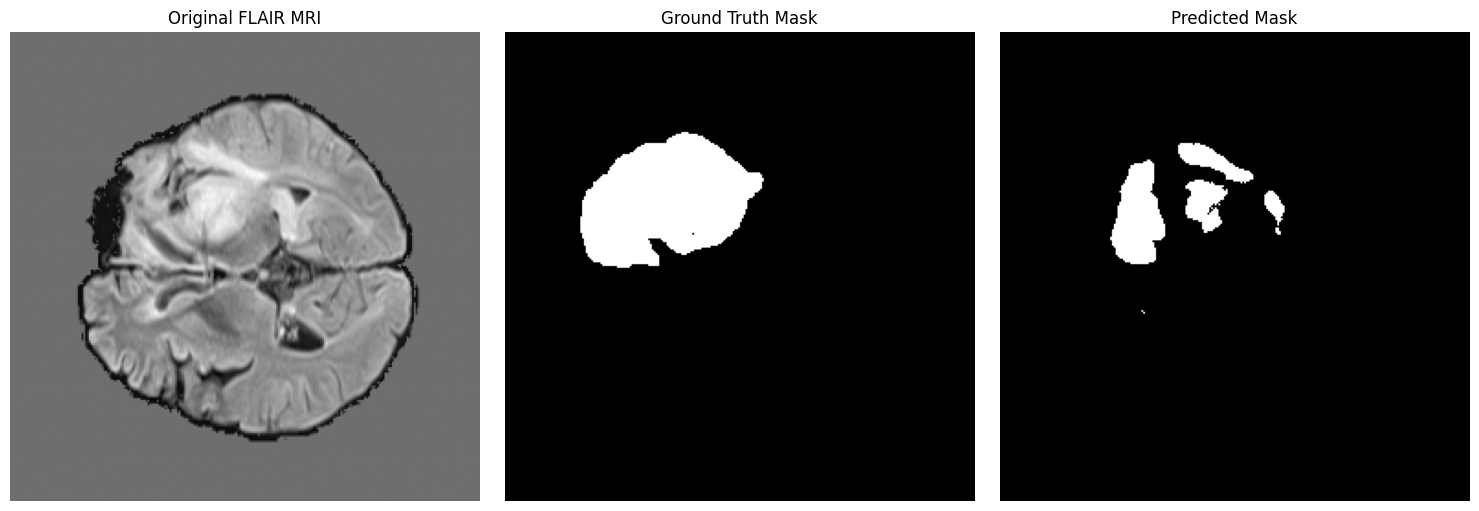

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

motum_flair_model.eval()

sample_index = 10

image, mask = test_dataset[sample_index]

with torch.no_grad():
    input_tensor = image.unsqueeze(0).to(device)

    output = motum_flair_model(input_tensor)
    probability = torch.sigmoid(output)

    prediction = (probability > 0.50).float()

# Select FLAIR channel
flair_image = image[0].cpu().numpy()
ground_truth = mask[0].cpu().numpy()
predicted_mask = prediction[0, 0].cpu().numpy()

print("MOTUM FLAIR PREDICTION ANALYSIS")
print("--------------------------------")
print("Sample Index:", sample_index)
print("Ground Truth Pixels:", int(ground_truth.sum()))
print("Predicted Pixels:", int(predicted_mask.sum()))
print("Threshold: 0.50")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(flair_image, cmap="gray")
axes[0].set_title("Original FLAIR MRI")

axes[1].imshow(ground_truth, cmap="gray")
axes[1].set_title("Ground Truth Mask")

axes[2].imshow(predicted_mask, cmap="gray")
axes[2].set_title("Predicted Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Step 27.42 — Individual Sample Performance

In [ ]:
import torch

motum_flair_model.eval()

image, mask = test_dataset[10]

with torch.no_grad():
    input_tensor = image.unsqueeze(0).to(device)
    output = motum_flair_model(input_tensor)

    prediction = (torch.sigmoid(output) > 0.50).float()
    target = mask.unsqueeze(0).to(device)

TP = ((prediction == 1) & (target == 1)).sum().item()
FP = ((prediction == 1) & (target == 0)).sum().item()
FN = ((prediction == 0) & (target == 1)).sum().item()

dice = (2 * TP) / (2 * TP + FP + FN + 1e-8)
iou = TP / (TP + FP + FN + 1e-8)
precision = TP / (TP + FP + 1e-8)
recall = TP / (TP + FN + 1e-8)

print("SAMPLE 10 PERFORMANCE")
print("----------------------")
print("TP:", TP)
print("FP:", FP)
print("FN:", FN)
print(f"Dice: {dice:.4f}")
print(f"IoU: {iou:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

SAMPLE 10 PERFORMANCE
----------------------
TP: 1903
FP: 176
FN: 3062
Dice: 0.5403
IoU: 0.3702
Precision: 0.9153
Recall: 0.3833


Step 27.43 — All Test Samples Individual Performance

In [ ]:
import torch
import pandas as pd
import os

motum_flair_model.eval()

sample_results = []

with torch.no_grad():
    for index in range(len(test_dataset)):

        image, mask = test_dataset[index]

        image = image.unsqueeze(0).to(device)
        mask = mask.unsqueeze(0).to(device)

        output = motum_flair_model(image)
        prediction = (torch.sigmoid(output) > 0.50).float()

        TP = ((prediction == 1) & (mask == 1)).sum().item()
        FP = ((prediction == 1) & (mask == 0)).sum().item()
        FN = ((prediction == 0) & (mask == 1)).sum().item()

        dice = (2 * TP) / (2 * TP + FP + FN + 1e-8)
        iou = TP / (TP + FP + FN + 1e-8)
        precision = TP / (TP + FP + 1e-8)
        recall = TP / (TP + FN + 1e-8)

        sample_results.append({
            "Sample_Index": index,
            "TP": TP,
            "FP": FP,
            "FN": FN,
            "Dice": dice,
            "IoU": iou,
            "Precision": precision,
            "Recall": recall
        })

sample_df = pd.DataFrame(sample_results)

save_path = os.path.join(
    OUTPUT_DIR,
    "MOTUM_FLAIR_individual_test_results.csv"
)

sample_df.to_csv(save_path, index=False)

print("INDIVIDUAL TEST ANALYSIS COMPLETED")
print("-----------------------------------")
print("Total Samples:", len(sample_df))
print("Average Dice:", round(sample_df["Dice"].mean(), 4))
print("Average IoU:", round(sample_df["IoU"].mean(), 4))
print("Average Precision:", round(sample_df["Precision"].mean(), 4))
print("Average Recall:", round(sample_df["Recall"].mean(), 4))
print("Best Dice:", round(sample_df["Dice"].max(), 4))
print("Worst Dice:", round(sample_df["Dice"].min(), 4))
print("Saved:", save_path)

INDIVIDUAL TEST ANALYSIS COMPLETED
-----------------------------------
Total Samples: 216
Average Dice: 0.3786
Average IoU: 0.3176
Average Precision: 0.4633
Average Recall: 0.371
Best Dice: 0.9726
Worst Dice: 0.0
Saved: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/MOTUM_FLAIR_individual_test_results.csv


Step 27.44 — Restore Individual Test Results

In [ ]:
import os
import pandas as pd

# Restore saved individual results
RESULT_PATH = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/MOTUM_FLAIR_individual_test_results.csv"

if not os.path.exists(RESULT_PATH):
    raise FileNotFoundError("Individual results CSV not found.")

sample_df = pd.read_csv(RESULT_PATH)

# Calculate pixel counts
sample_df["GT_Pixels"] = sample_df["TP"] + sample_df["FN"]
sample_df["Predicted_Pixels"] = sample_df["TP"] + sample_df["FP"]

# Separate empty and non-empty masks
empty_gt = sample_df[sample_df["GT_Pixels"] == 0]
nonempty_gt = sample_df[sample_df["GT_Pixels"] > 0]

# Calculate global Dice
total_tp = sample_df["TP"].sum()
total_fp = sample_df["FP"].sum()
total_fn = sample_df["FN"].sum()

global_dice = (2 * total_tp) / (
    2 * total_tp + total_fp + total_fn + 1e-8
)

print("MOTUM FLAIR EMPTY MASK ANALYSIS")
print("--------------------------------")
print("Total Test Samples:", len(sample_df))
print("Empty Ground Truth Samples:", len(empty_gt))
print("Non-empty Ground Truth Samples:", len(nonempty_gt))

print("\nDICE SCORE ANALYSIS")
print("--------------------------------")
print("All Sample Average Dice:",
      round(sample_df["Dice"].mean(), 4))
print("Non-empty Sample Average Dice:",
      round(nonempty_gt["Dice"].mean(), 4))
print("Global Pixel Dice:", round(global_dice, 4))

print("\nEMPTY MASK PREDICTION")
print("--------------------------------")
print("Empty GT with Empty Prediction:",
      len(empty_gt[empty_gt["Predicted_Pixels"] == 0]))
print("Empty GT with False Positive Prediction:",
      len(empty_gt[empty_gt["Predicted_Pixels"] > 0]))

print("\nBEST AND WORST SAMPLES")
print("--------------------------------")
print("Best Sample:")
print(sample_df.loc[sample_df["Dice"].idxmax()].to_string())

print("\nWorst Sample:")
print(sample_df.loc[sample_df["Dice"].idxmin()].to_string())

MOTUM FLAIR EMPTY MASK ANALYSIS
--------------------------------
Total Test Samples: 216
Empty Ground Truth Samples: 92
Non-empty Ground Truth Samples: 124

DICE SCORE ANALYSIS
--------------------------------
All Sample Average Dice: 0.3786
Non-empty Sample Average Dice: 0.6595
Global Pixel Dice: 0.7337

EMPTY MASK PREDICTION
--------------------------------
Empty GT with Empty Prediction: 68
Empty GT with False Positive Prediction: 24

BEST AND WORST SAMPLES
--------------------------------
Best Sample:
Sample_Index         103.000000
TP                  6126.000000
FP                   120.000000
FN                   225.000000
Dice                   0.972613
IoU                    0.946685
Precision              0.980788
Recall                 0.964573
GT_Pixels           6351.000000
Predicted_Pixels    6246.000000

Worst Sample:
Sample_Index        0.0
TP                  0.0
FP                  0.0
FN                  0.0
Dice                0.0
IoU                 0.0
Precision 

Step 27.45 — Corrected Individual Dice Analysis

In [ ]:
import numpy as np
import pandas as pd

sample_df["Corrected_Dice"] = sample_df["Dice"].copy()

empty_both = (
    (sample_df["GT_Pixels"] == 0) &
    (sample_df["Predicted_Pixels"] == 0)
)

sample_df.loc[empty_both, "Corrected_Dice"] = 1.0

print("CORRECTED MOTUM FLAIR DICE ANALYSIS")
print("-----------------------------------")
print("Total Samples:", len(sample_df))
print("Empty-Empty Samples:", int(empty_both.sum()))

print("Corrected Average Dice:",
      round(sample_df["Corrected_Dice"].mean(), 4))

print("Non-empty Average Dice:",
      round(sample_df.loc[
          sample_df["GT_Pixels"] > 0, "Dice"
      ].mean(), 4))

print("Global Pixel Dice:",
      round(global_dice, 4))

CORRECTED MOTUM FLAIR DICE ANALYSIS
-----------------------------------
Total Samples: 216
Empty-Empty Samples: 68
Corrected Average Dice: 0.6934
Non-empty Average Dice: 0.6595
Global Pixel Dice: 0.7337


Step 27.46 — MOTUM FLAIR Error Analysis Report Save

In [ ]:
import os
import pandas as pd

# Set paths
BASE_PATH = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"
OUTPUT_DIR = os.path.join(BASE_PATH, "model_outputs")

os.makedirs(OUTPUT_DIR, exist_ok=True)

csv_path = os.path.join(
    OUTPUT_DIR,
    "MOTUM_FLAIR_individual_test_results.csv"
)

# Load results
df = pd.read_csv(csv_path)

# Standardize column names
df.columns = df.columns.str.strip()

print("Available CSV Columns:")
print(df.columns.tolist())

# Check required columns
required = ["TP", "FP", "FN", "Dice"]
missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(
        f"Required columns missing: {missing}. "
        "Check the printed column names."
    )

# Calculate ground truth and predicted pixels
df["GT_Pixels"] = df["TP"] + df["FN"]
df["Predicted_Pixels"] = df["TP"] + df["FP"]

# Correct empty-empty Dice
empty_empty = (
    (df["GT_Pixels"] == 0) &
    (df["Predicted_Pixels"] == 0)
)

df["Corrected_Dice"] = df["Dice"]
df.loc[empty_empty, "Corrected_Dice"] = 1.0

# Calculate metrics
total_samples = len(df)
empty_empty_count = int(empty_empty.sum())

non_empty_df = df[df["GT_Pixels"] > 0]

corrected_avg_dice = df["Corrected_Dice"].mean()
non_empty_avg_dice = non_empty_df["Dice"].mean()

total_tp = df["TP"].sum()
total_fp = df["FP"].sum()
total_fn = df["FN"].sum()

denominator = 2 * total_tp + total_fp + total_fn

global_dice = (
    (2 * total_tp / denominator)
    if denominator > 0 else 1.0
)

# Save corrected CSV
corrected_csv = os.path.join(
    OUTPUT_DIR,
    "MOTUM_FLAIR_corrected_individual_results.csv"
)

df.to_csv(corrected_csv, index=False)

# Save report
report = f"""
MOTUM FLAIR ERROR ANALYSIS REPORT
=================================

Total Test Samples: {total_samples}
Empty-Empty Samples: {empty_empty_count}

Corrected Average Dice: {corrected_avg_dice:.4f}
Non-empty Sample Average Dice: {non_empty_avg_dice:.4f}
Global Pixel Dice: {global_dice:.4f}

Model: 2D U-Net
Dataset: MOTUM
Target: FLAIR
Threshold: 0.50

Empty-empty samples are assigned Dice = 1.0.
Non-empty Average Dice considers only samples
with non-empty ground-truth masks.

Global Pixel Dice is calculated using total TP, FP and FN.
"""

report_path = os.path.join(
    OUTPUT_DIR,
    "MOTUM_FLAIR_error_analysis_report.md"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

print("\nMOTUM FLAIR ERROR ANALYSIS SAVED")
print("--------------------------------")
print("Total Samples:", total_samples)
print("Empty-Empty Samples:", empty_empty_count)
print("Corrected Average Dice:", round(corrected_avg_dice, 4))
print("Non-empty Average Dice:", round(non_empty_avg_dice, 4))
print("Global Pixel Dice:", round(global_dice, 4))

print("\nSaved Files:")
print(report_path)
print(corrected_csv)

Available CSV Columns:
['Sample_Index', 'TP', 'FP', 'FN', 'Dice', 'IoU', 'Precision', 'Recall']

MOTUM FLAIR ERROR ANALYSIS SAVED
--------------------------------
Total Samples: 216
Empty-Empty Samples: 68
Corrected Average Dice: 0.6934
Non-empty Average Dice: 0.6595
Global Pixel Dice: 0.7337

Saved Files:
/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/MOTUM_FLAIR_error_analysis_report.md
/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/MOTUM_FLAIR_corrected_individual_results.csv


Step 27.47.1 — Loading and Verifying the T1CE Dataset

In [ ]:

import os
import glob
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Dataset path
BASE_PATH = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/MOTUM_2D_slices"

# Check dataset directory
if not os.path.isdir(BASE_PATH):
    raise FileNotFoundError(f"Dataset directory not found: {BASE_PATH}")

# Select device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# T1CE Dataset Class
class MOTUMT1CEDataset(Dataset):
    def __init__(self, split, image_size=256):
        self.split_dir = os.path.join(BASE_PATH, split)
        self.files = sorted(glob.glob(os.path.join(self.split_dir, "*.npz")))
        self.image_size = image_size

        if len(self.files) == 0:
            raise FileNotFoundError(
                f"No NPZ files found in {self.split_dir}"
            )

        # Verify required keys in first file
        with np.load(self.files[0]) as data:
            required_keys = ["images", "t1ce_mask"]
            missing = [key for key in required_keys if key not in data.files]

            if missing:
                raise ValueError(f"Missing keys: {missing}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        file_path = self.files[index]

        with np.load(file_path) as data:
            image = data["images"].astype(np.float32)
            mask = data["t1ce_mask"].astype(np.float32)

        # Convert image from HWC to CHW
        if image.ndim != 3 or image.shape[-1] != 4:
            raise ValueError(
                f"Unexpected image shape {image.shape} in {file_path}"
            )

        image = torch.from_numpy(image).permute(2, 0, 1)

        # Prepare mask
        if mask.ndim == 3 and mask.shape[-1] == 1:
            mask = mask[..., 0]

        if mask.ndim != 2:
            raise ValueError(
                f"Unexpected mask shape {mask.shape} in {file_path}"
            )

        mask = torch.from_numpy(mask).unsqueeze(0)

        # Resize image and mask
        image = F.interpolate(
            image.unsqueeze(0),
            size=(self.image_size, self.image_size),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)

        mask = F.interpolate(
            mask.unsqueeze(0),
            size=(self.image_size, self.image_size),
            mode="nearest"
        ).squeeze(0)

        # Convert mask to binary
        mask = (mask > 0).float()

        return image, mask


# Create datasets
train_dataset = MOTUMT1CEDataset("train")
val_dataset = MOTUMT1CEDataset("validation")
test_dataset = MOTUMT1CEDataset("test")

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=4, shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=4, shuffle=False, num_workers=0
)

# Verify dataset sizes
print("\nMOTUM T1CE DATASET VERIFICATION")
print("--------------------------------")
print("Train Samples:", len(train_dataset))
print("Validation Samples:", len(val_dataset))
print("Test Samples:", len(test_dataset))
print("Total Samples:", len(train_dataset) + len(val_dataset) + len(test_dataset))

# Verify one batch
images, masks = next(iter(train_loader))

print("\nBATCH VERIFICATION")
print("------------------")
print("Image Shape:", images.shape)
print("Mask Shape:", masks.shape)
print("Image Data Type:", images.dtype)
print("Mask Data Type:", masks.dtype)
print("Image Finite:", torch.isfinite(images).all().item())
print("Mask Unique Values:", torch.unique(masks).tolist())
print("Input Channels:", images.shape[1])

# Count empty and non-empty masks
empty_count = 0
non_empty_count = 0

for _, batch_masks in train_loader:
    for mask in batch_masks:
        if mask.sum().item() == 0:
            empty_count += 1
        else:
            non_empty_count += 1

print("\nTRAIN MASK DISTRIBUTION")
print("-----------------------")
print("Empty Masks:", empty_count)
print("Non-empty Masks:", non_empty_count)

print("\nT1CE DATASET READY")


Device: cpu

MOTUM T1CE DATASET VERIFICATION
--------------------------------
Train Samples: 929
Validation Samples: 225
Test Samples: 216
Total Samples: 1370

BATCH VERIFICATION
------------------
Image Shape: torch.Size([4, 4, 256, 256])
Mask Shape: torch.Size([4, 1, 256, 256])
Image Data Type: torch.float32
Mask Data Type: torch.float32
Image Finite: True
Mask Unique Values: [0.0, 1.0]
Input Channels: 4

TRAIN MASK DISTRIBUTION
-----------------------
Empty Masks: 646
Non-empty Masks: 283

T1CE DATASET READY


Step 27.47.2 — Creation of MOTUM T1CE U-Net Model

In [9]:

import torch
import torch.nn as nn

# Define Double Convolution Block
class T1CEDoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# Define T1CE U-Net
class MOTUMT1CEUNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder1 = T1CEDoubleConv(4, 16)
        self.encoder2 = T1CEDoubleConv(16, 32)
        self.encoder3 = T1CEDoubleConv(32, 64)
        self.encoder4 = T1CEDoubleConv(64, 128)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = T1CEDoubleConv(128, 256)

        # Decoder
        self.up4 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.decoder4 = T1CEDoubleConv(256, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.decoder3 = T1CEDoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.decoder2 = T1CEDoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.decoder1 = T1CEDoubleConv(32, 16)

        # Output layer
        self.output_layer = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder
        d4 = self.up4(b)
        d4 = self.decoder4(torch.cat([e4, d4], dim=1))

        d3 = self.up3(d4)
        d3 = self.decoder3(torch.cat([e3, d3], dim=1))

        d2 = self.up2(d3)
        d2 = self.decoder2(torch.cat([e2, d2], dim=1))

        d1 = self.up1(d2)
        d1 = self.decoder1(torch.cat([e1, d1], dim=1))

        return self.output_layer(d1)


# Initialize model
t1ce_model = MOTUMT1CEUNet().to(DEVICE)

# Count parameters
total_parameters = sum(
    parameter.numel()
    for parameter in t1ce_model.parameters()
)

# Test model output
sample_images, sample_masks = next(iter(train_loader))
sample_images = sample_images.to(DEVICE)

with torch.no_grad():
    sample_output = t1ce_model(sample_images)

# Display architecture verification
print("MOTUM T1CE U-NET MODEL VERIFICATION")
print("-----------------------------------")
print("Device:", DEVICE)
print("Input Shape:", sample_images.shape)
print("Output Shape:", sample_output.shape)
print("Target Mask Shape:", sample_masks.shape)
print("Total Parameters:", total_parameters)

print("Output Shape Match:",
      sample_output.shape == sample_masks.to(DEVICE).shape)

print("Model Created Successfully")


MOTUM T1CE U-NET MODEL VERIFICATION
-----------------------------------
Device: cpu
Input Shape: torch.Size([4, 4, 256, 256])
Output Shape: torch.Size([4, 1, 256, 256])
Target Mask Shape: torch.Size([4, 1, 256, 256])
Total Parameters: 1944193
Output Shape Match: True
Model Created Successfully


Step 27.47.3 — T1CE Model Training ও Checkpoint Saving

In [10]:

import os
import time
import torch
import torch.nn as nn

# Check required variables
required_variables = [
    "t1ce_model",
    "train_loader",
    "val_loader",
    "DEVICE"
]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"{variable} is not defined. "
            "Run the previous setup cells first."
        )

# Output directory
BASE_PATH = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"
OUTPUT_DIR = os.path.join(BASE_PATH, "model_outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

CHECKPOINT_PATH = os.path.join(
    OUTPUT_DIR,
    "motum_t1ce_unet_best.pth"
)

# Training configuration
EPOCHS = 1
LEARNING_RATE = 0.0005

# Loss functions
bce_loss = nn.BCEWithLogitsLoss()

def dice_loss_function(logits, targets):
    probabilities = torch.sigmoid(logits)

    intersection = (probabilities * targets).sum()
    total = probabilities.sum() + targets.sum()

    dice = (2.0 * intersection + 1e-6) / (total + 1e-6)

    return 1.0 - dice


# Combined loss
def combined_loss(logits, targets):
    loss_bce = bce_loss(logits, targets)
    loss_dice = dice_loss_function(logits, targets)

    return loss_bce + loss_dice


# Optimizer
optimizer = torch.optim.Adam(
    t1ce_model.parameters(),
    lr=LEARNING_RATE
)


# Metric calculation
def calculate_epoch_metrics(tp, fp, fn):
    dice = (2 * tp) / (2 * tp + fp + fn + 1e-8)
    iou = tp / (tp + fp + fn + 1e-8)

    return dice, iou


# Training and validation
best_val_dice = -1.0

print("MOTUM T1CE U-NET TRAINING")
print("--------------------------------")
print("Device:", DEVICE)
print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Training Samples:", len(train_loader.dataset))
print("Validation Samples:", len(val_loader.dataset))

start_time = time.time()

for epoch in range(EPOCHS):

    # Training phase
    t1ce_model.train()

    train_loss_total = 0.0
    train_tp = 0
    train_fp = 0
    train_fn = 0

    for images, masks in train_loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        optimizer.zero_grad()

        outputs = t1ce_model(images)
        loss = combined_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        train_loss_total += loss.item()

        predictions = (torch.sigmoid(outputs) >= 0.5).float()

        train_tp += int(((predictions == 1) & (masks == 1)).sum().item())
        train_fp += int(((predictions == 1) & (masks == 0)).sum().item())
        train_fn += int(((predictions == 0) & (masks == 1)).sum().item())

    train_loss = train_loss_total / len(train_loader)
    train_dice, train_iou = calculate_epoch_metrics(
        train_tp, train_fp, train_fn
    )

    # Validation phase
    t1ce_model.eval()

    val_loss_total = 0.0
    val_tp = 0
    val_fp = 0
    val_fn = 0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            outputs = t1ce_model(images)
            loss = combined_loss(outputs, masks)

            val_loss_total += loss.item()

            predictions = (torch.sigmoid(outputs) >= 0.5).float()

            val_tp += int(((predictions == 1) & (masks == 1)).sum().item())
            val_fp += int(((predictions == 1) & (masks == 0)).sum().item())
            val_fn += int(((predictions == 0) & (masks == 1)).sum().item())

    val_loss = val_loss_total / len(val_loader)
    val_dice, val_iou = calculate_epoch_metrics(
        val_tp, val_fp, val_fn
    )

    # Save best checkpoint
    if val_dice > best_val_dice:

        best_val_dice = val_dice

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": t1ce_model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "validation_dice": val_dice,
                "input_channels": 4,
                "target": "T1CE"
            },
            CHECKPOINT_PATH
        )

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print("--------------------------------")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Dice: {train_dice:.4f}")
    print(f"Train IoU: {train_iou:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Dice: {val_dice:.4f}")
    print(f"Validation IoU: {val_iou:.4f}")

training_time = (time.time() - start_time) / 60

print("\nTRAINING COMPLETED")
print("--------------------------------")
print("Best Validation Dice:", round(best_val_dice, 4))
print("Training Time:", round(training_time, 2), "minutes")
print("Checkpoint Exists:", os.path.exists(CHECKPOINT_PATH))
print("Checkpoint Path:", CHECKPOINT_PATH)


MOTUM T1CE U-NET TRAINING
--------------------------------
Device: cpu
Epochs: 1
Learning Rate: 0.0005
Training Samples: 929
Validation Samples: 225

Epoch 1/1
--------------------------------
Train Loss: 1.4184
Train Dice: 0.1963
Train IoU: 0.1088
Validation Loss: 1.3023
Validation Dice: 0.4157
Validation IoU: 0.2624

TRAINING COMPLETED
--------------------------------
Best Validation Dice: 0.4157
Training Time: 10.4 minutes
Checkpoint Exists: True
Checkpoint Path: /content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/motum_t1ce_unet_best.pth


Step 27.47.4 — MOTUM T1CE Test Evaluation

In [11]:
import os
import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# Step 1: Set paths and device
BASE_PATH = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"
OUTPUT_DIR = os.path.join(BASE_PATH, "model_outputs")
CHECKPOINT_PATH = os.path.join(
    OUTPUT_DIR, "motum_t1ce_unet_best.pth"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
THRESHOLD = 0.50

# Step 2: Verify required objects and checkpoint
if "test_loader" not in globals():
    raise NameError("test_loader is missing. Restore the T1CE test DataLoader first.")

if "t1ce_model" not in globals():
    raise NameError("t1ce_model is missing. Recreate the T1CE U-Net model first.")

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT_PATH}")

# Step 3: Load the saved model
try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)

t1ce_model.load_state_dict(checkpoint["model_state_dict"])
t1ce_model = t1ce_model.to(DEVICE)
t1ce_model.eval()

print("MOTUM T1CE TEST EVALUATION")
print("--------------------------------")
print("Device:", DEVICE)
print("Checkpoint Loaded: True")
print("Test Samples:", len(test_loader.dataset))
print("Threshold:", THRESHOLD)

# Step 4: Evaluate the test dataset
total_tp = 0
total_fp = 0
total_fn = 0
total_tn = 0

individual_results = []

with torch.no_grad():
    for batch_index, (images, masks) in enumerate(
        tqdm(test_loader, desc="Testing")
    ):
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        logits = t1ce_model(images)
        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= THRESHOLD).float()

        # Pixel-level counts
        tp = ((predictions == 1) & (masks == 1)).sum().item()
        fp = ((predictions == 1) & (masks == 0)).sum().item()
        fn = ((predictions == 0) & (masks == 1)).sum().item()
        tn = ((predictions == 0) & (masks == 0)).sum().item()

        total_tp += tp
        total_fp += fp
        total_fn += fn
        total_tn += tn

        # Individual sample metrics
        for i in range(images.size(0)):
            pred_i = predictions[i]
            mask_i = masks[i]

            sample_tp = ((pred_i == 1) & (mask_i == 1)).sum().item()
            sample_fp = ((pred_i == 1) & (mask_i == 0)).sum().item()
            sample_fn = ((pred_i == 0) & (mask_i == 1)).sum().item()

            denominator = (2 * sample_tp) + sample_fp + sample_fn

            if denominator == 0:
                sample_dice = 1.0
            else:
                sample_dice = (2 * sample_tp) / denominator

            sample_iou_denominator = sample_tp + sample_fp + sample_fn

            if sample_iou_denominator == 0:
                sample_iou = 1.0
            else:
                sample_iou = sample_tp / sample_iou_denominator

            individual_results.append({
                "Sample_Index": len(individual_results),
                "TP": sample_tp,
                "FP": sample_fp,
                "FN": sample_fn,
                "Dice": sample_dice,
                "IoU": sample_iou,
                "GT_Pixels": int(mask_i.sum().item()),
                "Predicted_Pixels": int(pred_i.sum().item())
            })

# Step 5: Calculate global metrics
dice = (2 * total_tp) / max(2 * total_tp + total_fp + total_fn, 1)
iou = total_tp / max(total_tp + total_fp + total_fn, 1)
precision = total_tp / max(total_tp + total_fp, 1)
recall = total_tp / max(total_tp + total_fn, 1)
specificity = total_tn / max(total_tn + total_fp, 1)
accuracy = (total_tp + total_tn) / max(
    total_tp + total_fp + total_fn + total_tn, 1
)

# Step 6: Display results
print("\nFINAL T1CE TEST RESULTS")
print("--------------------------------")
print("Test Samples:", len(individual_results))
print(f"Dice: {dice:.4f}")
print(f"IoU: {iou:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Accuracy: {accuracy:.4f}")

print("\nPIXEL COUNTS")
print("--------------------------------")
print("TP:", total_tp)
print("FP:", total_fp)
print("FN:", total_fn)
print("TN:", total_tn)

# Step 7: Save summary results
summary_df = pd.DataFrame([{
    "Dataset": "MOTUM",
    "Target": "T1CE",
    "Model": "2D U-Net",
    "Test_Samples": len(individual_results),
    "Threshold": THRESHOLD,
    "Dice": dice,
    "IoU": iou,
    "Precision": precision,
    "Recall": recall,
    "Specificity": specificity,
    "Accuracy": accuracy,
    "TP": total_tp,
    "FP": total_fp,
    "FN": total_fn,
    "TN": total_tn
}])

summary_path = os.path.join(
    OUTPUT_DIR, "MOTUM_T1CE_final_test_results.csv"
)
summary_df.to_csv(summary_path, index=False)

# Step 8: Save individual sample results
individual_df = pd.DataFrame(individual_results)

individual_path = os.path.join(
    OUTPUT_DIR, "MOTUM_T1CE_individual_test_results.csv"
)
individual_df.to_csv(individual_path, index=False)

print("\nRESULTS SAVED")
print("--------------------------------")
print(summary_path)
print(individual_path)
print("Test Evaluation Completed")

MOTUM T1CE TEST EVALUATION
--------------------------------
Device: cpu
Checkpoint Loaded: True
Test Samples: 216
Threshold: 0.5


Testing:   0%|          | 0/54 [00:00<?, ?it/s]


FINAL T1CE TEST RESULTS
--------------------------------
Test Samples: 216
Dice: 0.2420
IoU: 0.1377
Precision: 0.1452
Recall: 0.7255
Specificity: 0.9694
Accuracy: 0.9677

PIXEL COUNTS
--------------------------------
TP: 73028
FP: 429834
FN: 27628
TN: 13625286

RESULTS SAVED
--------------------------------
/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/MOTUM_T1CE_final_test_results.csv
/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/MOTUM_T1CE_individual_test_results.csv
Test Evaluation Completed


Step 27.47.5 — MOTUM T1CE Error Analysis

In [12]:
import os
import numpy as np
import pandas as pd

BASE_PATH = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"
OUTPUT_DIR = os.path.join(BASE_PATH, "model_outputs")

CSV_PATH = os.path.join(
    OUTPUT_DIR, "MOTUM_T1CE_individual_test_results.csv"
)

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"Individual results not found: {CSV_PATH}")

df = pd.read_csv(CSV_PATH)

# Identify empty and non-empty ground-truth samples
df["Empty_GT"] = df["GT_Pixels"] == 0
df["Empty_Prediction"] = df["Predicted_Pixels"] == 0

empty_gt = df[df["Empty_GT"]]
non_empty_gt = df[~df["Empty_GT"]]

empty_empty = df[
    df["Empty_GT"] & df["Empty_Prediction"]
]

empty_with_fp = df[
    df["Empty_GT"] & ~df["Empty_Prediction"]
]

# Calculate sample-level averages
corrected_average_dice = df["Dice"].mean()

non_empty_average_dice = (
    non_empty_gt["Dice"].mean()
    if len(non_empty_gt) > 0 else 0
)

average_iou = df["IoU"].mean()

# Find best and worst non-empty samples
if len(non_empty_gt) > 0:
    best_sample = non_empty_gt.loc[non_empty_gt["Dice"].idxmax()]
    worst_sample = non_empty_gt.loc[non_empty_gt["Dice"].idxmin()]
else:
    best_sample = None
    worst_sample = None

# Display analysis
print("MOTUM T1CE ERROR ANALYSIS")
print("--------------------------------")
print("Total Test Samples:", len(df))
print("Empty Ground Truth:", len(empty_gt))
print("Non-empty Ground Truth:", len(non_empty_gt))
print("Empty GT + Empty Prediction:", len(empty_empty))
print("Empty GT + False Positive:", len(empty_with_fp))

print("\nSAMPLE-LEVEL PERFORMANCE")
print("--------------------------------")
print(f"Corrected Average Dice: {corrected_average_dice:.4f}")
print(f"Non-empty Average Dice: {non_empty_average_dice:.4f}")
print(f"Average IoU: {average_iou:.4f}")

if best_sample is not None:
    print("\nBEST NON-EMPTY SAMPLE")
    print("--------------------------------")
    print("Sample Index:", int(best_sample["Sample_Index"]))
    print(f"Dice: {best_sample['Dice']:.4f}")
    print(f"IoU: {best_sample['IoU']:.4f}")
    print("GT Pixels:", int(best_sample["GT_Pixels"]))
    print("Predicted Pixels:", int(best_sample["Predicted_Pixels"]))

    print("\nWORST NON-EMPTY SAMPLE")
    print("--------------------------------")
    print("Sample Index:", int(worst_sample["Sample_Index"]))
    print(f"Dice: {worst_sample['Dice']:.4f}")
    print(f"IoU: {worst_sample['IoU']:.4f}")
    print("GT Pixels:", int(worst_sample["GT_Pixels"]))
    print("Predicted Pixels:", int(worst_sample["Predicted_Pixels"]))

# Save error analysis report
report_path = os.path.join(
    OUTPUT_DIR, "MOTUM_T1CE_error_analysis_report.md"
)

report = f"""# MOTUM T1CE Error Analysis

## Dataset
- Total test samples: {len(df)}
- Empty ground-truth samples: {len(empty_gt)}
- Non-empty ground-truth samples: {len(non_empty_gt)}
- Empty GT and empty prediction: {len(empty_empty)}
- Empty GT with false-positive prediction: {len(empty_with_fp)}

## Sample-level Metrics
- Corrected average Dice: {corrected_average_dice:.4f}
- Non-empty average Dice: {non_empty_average_dice:.4f}
- Average IoU: {average_iou:.4f}

## Interpretation
The model's test performance indicates that false-positive predictions
require further investigation. Sample-level metrics are reported separately
from the global pixel-level test metrics.
"""

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

print("\nERROR ANALYSIS REPORT SAVED")
print("--------------------------------")
print(report_path)

MOTUM T1CE ERROR ANALYSIS
--------------------------------
Total Test Samples: 216
Empty Ground Truth: 140
Non-empty Ground Truth: 76
Empty GT + Empty Prediction: 97
Empty GT + False Positive: 43

SAMPLE-LEVEL PERFORMANCE
--------------------------------
Corrected Average Dice: 0.5702
Non-empty Average Dice: 0.3441
Average IoU: 0.5310

BEST NON-EMPTY SAMPLE
--------------------------------
Sample Index: 76
Dice: 0.7751
IoU: 0.6328
GT Pixels: 3505
Predicted Pixels: 5392

WORST NON-EMPTY SAMPLE
--------------------------------
Sample Index: 61
Dice: 0.0000
IoU: 0.0000
GT Pixels: 183
Predicted Pixels: 0

ERROR ANALYSIS REPORT SAVED
--------------------------------
/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET/model_outputs/MOTUM_T1CE_error_analysis_report.md


Step 27.48 — MOTUM FLAIR ও T1CE Baseline Comparison Report

In [13]:
import os
import pandas as pd
import numpy as np

# Step 1: Define paths
BASE_PATH = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"
OUTPUT_DIR = os.path.join(BASE_PATH, "model_outputs")

FLAIR_SUMMARY = os.path.join(
    OUTPUT_DIR, "MOTUM_FLAIR_final_test_results.csv"
)

T1CE_SUMMARY = os.path.join(
    OUTPUT_DIR, "MOTUM_T1CE_final_test_results.csv"
)

FLAIR_INDIVIDUAL = os.path.join(
    OUTPUT_DIR, "MOTUM_FLAIR_corrected_individual_results.csv"
)

T1CE_INDIVIDUAL = os.path.join(
    OUTPUT_DIR, "MOTUM_T1CE_individual_test_results.csv"
)

# Step 2: Check required files
required_files = [
    FLAIR_SUMMARY,
    T1CE_SUMMARY,
    FLAIR_INDIVIDUAL,
    T1CE_INDIVIDUAL
]

for file_path in required_files:
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"Required file not found: {file_path}")

# Step 3: Load saved results
flair_summary = pd.read_csv(FLAIR_SUMMARY).iloc[0]
t1ce_summary = pd.read_csv(T1CE_SUMMARY).iloc[0]

flair_individual = pd.read_csv(FLAIR_INDIVIDUAL)
t1ce_individual = pd.read_csv(T1CE_INDIVIDUAL)

# Step 4: Calculate sample-level error analysis
def analyze_samples(df):
    required_columns = ["TP", "FP", "FN", "Dice", "IoU"]

    for column in required_columns:
        if column not in df.columns:
            raise ValueError(f"Missing column: {column}")

    gt_pixels = df["TP"] + df["FN"]
    predicted_pixels = df["TP"] + df["FP"]

    empty_gt = gt_pixels == 0
    empty_prediction = predicted_pixels == 0

    non_empty = df.loc[~empty_gt]

    return {
        "Total Samples": len(df),
        "Empty GT": int(empty_gt.sum()),
        "Non-empty GT": int((~empty_gt).sum()),
        "Empty GT + Empty Prediction": int(
            (empty_gt & empty_prediction).sum()
        ),
        "Empty GT + False Positive": int(
            (empty_gt & ~empty_prediction).sum()
        ),
        "Corrected Average Dice": float(df["Dice"].mean()),
        "Non-empty Average Dice": float(
            non_empty["Dice"].mean()
        ) if len(non_empty) else 0.0,
        "Sample-wise Average IoU": float(df["IoU"].mean())
    }

flair_analysis = analyze_samples(flair_individual)
t1ce_analysis = analyze_samples(t1ce_individual)

# Step 5: Create comparison table
comparison = pd.DataFrame([
    {
        "Target": "FLAIR",
        "Model": "2D U-Net",
        "Train Loss": 1.1668,
        "Train Dice": 0.5063,
        "Validation Loss": 1.0432,
        "Validation Dice": 0.7336,
        "Global Test Dice": float(flair_summary["Dice"]),
        "Global Test IoU": float(flair_summary["IoU"]),
        "Precision": float(flair_summary["Precision"]),
        "Recall": float(flair_summary["Recall"]),
        "Non-empty Average Dice": flair_analysis["Non-empty Average Dice"],
        "Corrected Average Dice": flair_analysis["Corrected Average Dice"]
    },
    {
        "Target": "T1CE",
        "Model": "2D U-Net",
        "Train Loss": 1.4184,
        "Train Dice": 0.1963,
        "Validation Loss": 1.3023,
        "Validation Dice": 0.4157,
        "Global Test Dice": float(t1ce_summary["Dice"]),
        "Global Test IoU": float(t1ce_summary["IoU"]),
        "Precision": float(t1ce_summary["Precision"]),
        "Recall": float(t1ce_summary["Recall"]),
        "Non-empty Average Dice": t1ce_analysis["Non-empty Average Dice"],
        "Corrected Average Dice": t1ce_analysis["Corrected Average Dice"]
    }
])

# Step 6: Display comparison
print("MOTUM FLAIR VS T1CE BASELINE COMPARISON")
print("----------------------------------------")
print(comparison.round(4).to_string(index=False))

print("\nFLAIR ERROR ANALYSIS")
print("----------------------------------------")
for key, value in flair_analysis.items():
    print(f"{key}: {value:.4f}" if isinstance(value, float)
          else f"{key}: {value}")

print("\nT1CE ERROR ANALYSIS")
print("----------------------------------------")
for key, value in t1ce_analysis.items():
    print(f"{key}: {value:.4f}" if isinstance(value, float)
          else f"{key}: {value}")

# Step 7: Save comparison CSV
comparison_path = os.path.join(
    OUTPUT_DIR, "MOTUM_FLAIR_T1CE_baseline_comparison.csv"
)

comparison.to_csv(comparison_path, index=False)

# Step 8: Save Markdown report
report_path = os.path.join(
    OUTPUT_DIR, "MOTUM_FLAIR_T1CE_baseline_comparison.md"
)

report = f"""# MOTUM FLAIR and T1CE Baseline Comparison

## Experiment Setup
- Dataset: MOTUM
- Model: 2D U-Net
- Input: Four MRI modalities
- Input image size: 256 x 256
- Training epochs: 1
- Test samples per target: 216

## Global Test Results

{comparison.to_markdown(index=False)}

## FLAIR Error Analysis

{pd.DataFrame([flair_analysis]).to_markdown(index=False)}

## T1CE Error Analysis

{pd.DataFrame([t1ce_analysis]).to_markdown(index=False)}

## Interpretation

The preliminary FLAIR model achieved a higher global test Dice
than the T1CE model. The T1CE model showed a high false-positive
count and lower precision. These results are preliminary and
should not be interpreted as a definitive comparison of MRI
modalities because the target masks and segmentation difficulty
differ between the experiments.

Both models were trained for only one epoch. Further optimization
and evaluation are required.
"""

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

print("\nCOMPARISON FILES SAVED")
print("----------------------------------------")
print(comparison_path)
print(report_path)
print("Baseline Comparison Completed")

MOTUM FLAIR VS T1CE BASELINE COMPARISON
----------------------------------------
Target    Model  Train Loss  Train Dice  Validation Loss  Validation Dice  Global Test Dice  Global Test IoU  Precision  Recall  Non-empty Average Dice  Corrected Average Dice
 FLAIR 2D U-Net      1.1668      0.5063           1.0432           0.7336            0.7337           0.5794     0.6978  0.7734                  0.6595                  0.3786
  T1CE 2D U-Net      1.4184      0.1963           1.3023           0.4157            0.2420           0.1377     0.1452  0.7255                  0.3441                  0.5702

FLAIR ERROR ANALYSIS
----------------------------------------
Total Samples: 216
Empty GT: 92
Non-empty GT: 124
Empty GT + Empty Prediction: 68
Empty GT + False Positive: 24
Corrected Average Dice: 0.3786
Non-empty Average Dice: 0.6595
Sample-wise Average IoU: 0.3176

T1CE ERROR ANALYSIS
----------------------------------------
Total Samples: 216
Empty GT: 140
Non-empty GT: 76
Empty GT +

Step 27.48.1 — Corrected Sample-wise Comparison

In [14]:
import os
import pandas as pd
import numpy as np

BASE_PATH = "/content/drive/MyDrive/BRAIN TUMOR PROJECT DATASET"
OUTPUT_DIR = os.path.join(BASE_PATH, "model_outputs")

# Original individual result files
FLAIR_PATH = os.path.join(
    OUTPUT_DIR, "MOTUM_FLAIR_individual_test_results.csv"
)
T1CE_PATH = os.path.join(
    OUTPUT_DIR, "MOTUM_T1CE_individual_test_results.csv"
)

for path in [FLAIR_PATH, T1CE_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(path)

def calculate_corrected_metrics(path, target):
    df = pd.read_csv(path)

    required = ["TP", "FP", "FN"]
    for col in required:
        if col not in df.columns:
            raise ValueError(f"{target}: Missing column {col}")

    corrected_dice = []
    corrected_iou = []

    for _, row in df.iterrows():
        tp = int(row["TP"])
        fp = int(row["FP"])
        fn = int(row["FN"])

        dice_denominator = 2 * tp + fp + fn
        iou_denominator = tp + fp + fn

        if dice_denominator == 0:
            dice_value = 1.0
        else:
            dice_value = (2 * tp) / dice_denominator

        if iou_denominator == 0:
            iou_value = 1.0
        else:
            iou_value = tp / iou_denominator

        corrected_dice.append(dice_value)
        corrected_iou.append(iou_value)

    df["Corrected_Dice"] = corrected_dice
    df["Corrected_IoU"] = corrected_iou

    gt_pixels = df["TP"] + df["FN"]
    pred_pixels = df["TP"] + df["FP"]

    empty_gt = gt_pixels == 0
    empty_pred = pred_pixels == 0

    result = {
        "Target": target,
        "Total Samples": len(df),
        "Empty GT": int(empty_gt.sum()),
        "Non-empty GT": int((~empty_gt).sum()),
        "Empty GT + Empty Prediction": int(
            (empty_gt & empty_pred).sum()
        ),
        "Empty GT + False Positive": int(
            (empty_gt & ~empty_pred).sum()
        ),
        "Corrected Average Dice": float(
            df["Corrected_Dice"].mean()
        ),
        "Non-empty Average Dice": float(
            df.loc[~empty_gt, "Corrected_Dice"].mean()
        ),
        "Corrected Sample-wise Average IoU": float(
            df["Corrected_IoU"].mean()
        )
    }

    save_path = os.path.join(
        OUTPUT_DIR,
        f"MOTUM_{target}_corrected_individual_results.csv"
    )
    df.to_csv(save_path, index=False)

    return result, save_path

# Recalculate both targets
flair_result, flair_save = calculate_corrected_metrics(
    FLAIR_PATH, "FLAIR"
)

t1ce_result, t1ce_save = calculate_corrected_metrics(
    T1CE_PATH, "T1CE"
)

# Load global test metrics
flair_global = pd.read_csv(
    os.path.join(OUTPUT_DIR, "MOTUM_FLAIR_final_test_results.csv")
).iloc[0]

t1ce_global = pd.read_csv(
    os.path.join(OUTPUT_DIR, "MOTUM_T1CE_final_test_results.csv")
).iloc[0]

# Create final comparison
comparison = pd.DataFrame([
    {
        "Target": "FLAIR",
        "Model": "2D U-Net",
        "Train Dice": 0.5063,
        "Validation Dice": 0.7336,
        "Global Test Dice": flair_global["Dice"],
        "Global Test IoU": flair_global["IoU"],
        "Precision": flair_global["Precision"],
        "Recall": flair_global["Recall"],
        "Corrected Average Dice": flair_result["Corrected Average Dice"],
        "Non-empty Average Dice": flair_result["Non-empty Average Dice"],
        "Corrected Sample-wise Average IoU":
            flair_result["Corrected Sample-wise Average IoU"]
    },
    {
        "Target": "T1CE",
        "Model": "2D U-Net",
        "Train Dice": 0.1963,
        "Validation Dice": 0.4157,
        "Global Test Dice": t1ce_global["Dice"],
        "Global Test IoU": t1ce_global["IoU"],
        "Precision": t1ce_global["Precision"],
        "Recall": t1ce_global["Recall"],
        "Corrected Average Dice": t1ce_result["Corrected Average Dice"],
        "Non-empty Average Dice": t1ce_result["Non-empty Average Dice"],
        "Corrected Sample-wise Average IoU":
            t1ce_result["Corrected Sample-wise Average IoU"]
    }
])

print("CORRECTED MOTUM BASELINE COMPARISON")
print("----------------------------------------")
print(comparison.round(4).to_string(index=False))

print("\nFLAIR SAMPLE ANALYSIS")
for key, value in flair_result.items():
    print(f"{key}: {value:.4f}" if isinstance(value, float)
          else f"{key}: {value}")

print("\nT1CE SAMPLE ANALYSIS")
for key, value in t1ce_result.items():
    print(f"{key}: {value:.4f}" if isinstance(value, float)
          else f"{key}: {value}")

# Save final comparison CSV
comparison_csv = os.path.join(
    OUTPUT_DIR, "MOTUM_FLAIR_T1CE_baseline_comparison.csv"
)
comparison.to_csv(comparison_csv, index=False)

# Save final comparison report
comparison_md = os.path.join(
    OUTPUT_DIR, "MOTUM_FLAIR_T1CE_baseline_comparison.md"
)

report = f"""# Corrected MOTUM FLAIR and T1CE Baseline Comparison

Both models use four MRI input modalities and were trained for one epoch.

## Global Test Metrics

{comparison.to_markdown(index=False)}

## FLAIR Sample Analysis

{pd.DataFrame([flair_result]).to_markdown(index=False)}

## T1CE Sample Analysis

{pd.DataFrame([t1ce_result]).to_markdown(index=False)}

## Interpretation

Global pixel-level metrics and sample-wise average metrics are different
evaluation methods and should be reported separately.

Empty-ground-truth and empty-prediction samples receive a Dice and IoU
score of 1.0 in the corrected sample-wise analysis.

The FLAIR and T1CE results are preliminary baseline experiments.
The two targets have different mask distributions and difficulty.
Further training and optimization are required.
"""

with open(comparison_md, "w", encoding="utf-8") as f:
    f.write(report)

print("\nCORRECTED FILES SAVED")
print("----------------------------------------")
print(flair_save)
print(t1ce_save)
print(comparison_csv)
print(comparison_md)
print("Corrected Comparison Completed")

CORRECTED MOTUM BASELINE COMPARISON
----------------------------------------
Target    Model  Train Dice  Validation Dice  Global Test Dice  Global Test IoU  Precision  Recall  Corrected Average Dice  Non-empty Average Dice  Corrected Sample-wise Average IoU
 FLAIR 2D U-Net      0.5063           0.7336            0.7337           0.5794     0.6978  0.7734                  0.6934                  0.6595                             0.6324
  T1CE 2D U-Net      0.1963           0.4157            0.2420           0.1377     0.1452  0.7255                  0.5702                  0.3441                             0.5310

FLAIR SAMPLE ANALYSIS
Target: FLAIR
Total Samples: 216
Empty GT: 92
Non-empty GT: 124
Empty GT + Empty Prediction: 68
Empty GT + False Positive: 24
Corrected Average Dice: 0.6934
Non-empty Average Dice: 0.6595
Corrected Sample-wise Average IoU: 0.6324

T1CE SAMPLE ANALYSIS
Target: T1CE
Total Samples: 216
Empty GT: 140
Non-empty GT: 76
Empty GT + Empty Prediction: 97
Empty G